SALES ANALYSIS - AAL (AUSTRALIAN APPAREL LTD) - Q4 2020
=======================================================

PROBLEM DEFINITION:
==================

To analyze the fourth quarter (October to December 2020) sales of AAL state by state, to find the states with highest and lowest revenue and to suggest sales programs for the low revenue states, so that the Head of Sales and Marketing (S&M) can make data-driven decisions for the expansion.

Data description:
================

The dataset has the sales of AAL for Q4 2020 identifying sales group, unit, amount along with date, time and state

The project follows 4 steps,

 - STEP1 Data wrangling
 - STEP2 Data analysis
 - STEP3 Data visualization
 - STEP4 Report generation.

STEP1 : DATA WRANGLING

Import Data and examine Variables (DATA COLLECTION)

In [133]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statistics
from scipy import stats
pd.options.display.float_format = "{:,.2f}".format 
sns.set_theme(style="whitegrid")

# read the dataset into a pandas DataFrame

df = pd.read_csv("AusApparalSales4thQrt2020.csv") 

# print the shape of the dataset

df_rows,df_columns=df.shape
print("\n Dataset shape :-",
      "\n Number of Rows : ", df_rows,
      "\n Number of Columns : ", df_columns) 
print("\nPreview Dataset : ")
df.head(10)  # View the first 10 rows of the dataset


 Dataset shape :- 
 Number of Rows :  7560 
 Number of Columns :  6

Preview Dataset : 


,Date,Time,State,Group,Unit,Sales
0,1-Oct-2020,Morning,WA,Kids,8,20000
1,1-Oct-2020,Morning,WA,Men,8,20000
2,1-Oct-2020,Morning,WA,Women,4,10000
3,1-Oct-2020,Morning,WA,Seniors,15,37500
4,1-Oct-2020,Afternoon,WA,Kids,3,7500
5,1-Oct-2020,Afternoon,WA,Men,10,25000
6,1-Oct-2020,Afternoon,WA,Women,3,7500
7,1-Oct-2020,Afternoon,WA,Seniors,11,27500
8,1-Oct-2020,Evening,WA,Kids,15,37500
9,1-Oct-2020,Evening,WA,Men,15,37500


In [134]:
print("\nDataset Information : \n=====================\n")
print(df.info())  # check for the data types and null values in the dataset


Dataset Information : 

<class 'pandas.DataFrame'>
RangeIndex: 7560 entries, 0 to 7559
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Date    7560 non-null   str  
 1   Time    7560 non-null   str  
 2   State   7560 non-null   str  
 3   Group   7560 non-null   str  
 4   Unit    7560 non-null   int64
 5   Sales   7560 non-null   int64
dtypes: int64(2), str(4)
memory usage: 354.5 KB
None


In [135]:
# Check the unique values of the text columns, repr is used to show the hidden spaces

print("\nUnique values of text columns : \n===============================\n")
for c in ['Time', 'State', 'Group']:
    print(c, ":\n", "\n",[repr(v) for v in df[c].unique()],"\n")

print("\nFirst 8 values of Date column : \n\n", [repr(v) for v in df['Date'].head(8)],"\n")


Unique values of text columns : 

Time :
 
 ["' Morning'", "' Afternoon'", "' Evening'"] 

State :
 
 ["' WA'", "' NT'", "' SA'", "' VIC'", "' QLD'", "' NSW'", "' TAS'"] 

Group :
 
 ["' Kids'", "' Men'", "' Women'", "' Seniors'"] 


First 8 values of Date column : 

 ["'1-Oct-2020'", "'1-Oct-2020'", "'1-Oct-2020'", "'1-Oct-2020'", "'1-Oct-2020'", "'1-Oct-2020'", "'1-Oct-2020'", "'1-Oct-2020'"] 



OBSERVATION :

1. The dataset has 7,560 rows and 6 columns. Information shows "7560" non-null count for all the columns, so there is no missing value
2. "Time", "State" and "Group" values have a leading space, e.g. ' WA', so filters will not work until it is removed
3. "Date" column is categorized as STRING format but the values are dates (for example 1-Oct-2020), so it needs to be converted to date format
4. "Unit" and "Sales" are Integer format, which is correct

1.a Ensure that the data is clean and free from any missing or incorrect entries

1.a.1 Inspect the data manually to identify missing or incorrect information using the functions isna() and notna()

In [136]:
# Missing values check using isna() and notna()

isna_count = df.isna().sum()
print("\nMissing values in each column (isna) : \n=======================================\n")
print(isna_count)

notna_count = df.notna().sum() 
print("\nAvailable values in each column (notna) : \n=========================================\n")
print(notna_count)
print("\n Total number of Rows :", df_rows)

print("\nTotal missing values in the dataset (isna) : ", df.isna().sum().sum(),
      "\nTotal available values per column in the dataset matches the number of rows count (notna) : ", (notna_count == df_rows).all())


Missing values in each column (isna) : 

Date     0
Time     0
State    0
Group    0
Unit     0
Sales    0
dtype: int64

Available values in each column (notna) : 

Date     7560
Time     7560
State    7560
Group    7560
Unit     7560
Sales    7560
dtype: int64

 Total number of Rows : 7560

Total missing values in the dataset (isna) :  0 
Total available values per column in the dataset matches the number of rows count (notna) :  True


Based on the above check, notna() count is equal to the number of rows in all the six columns, so there is no missing value and nothing to drop or fill in this dataset.

1.a.2 Check for DUPLICATE data entries

In [137]:
# Duplicate rows check for incorrect entries  

duplicate_row_count = df.duplicated().sum()          # number of duplicate rows

print("Number of rows : ", df_rows)
print("Duplicate rows count : ", duplicate_row_count)

if duplicate_row_count == 0:
    print("\n No Duplicate entries in the data")
else:
    print("\n Duplicate entries found :")
    print(df[df.duplicated()])                    # rows that repeat an earlier row

Number of rows :  7560
Duplicate rows count :  0

 No Duplicate entries in the data


No duplicate rows are found, so no row needs to be removed.

1.a.3 DATA CLEANING

Issues identified in step1 need to be resolved 
- extra spaces in text columns
- the Date column format

In [138]:
# copy raw data for future reference, as we will be cleaning up the text columns and the Date column

df_raw = df.copy()                                     # untouched copy

print("\nText Columns before cleaning : \n===============================\n")
for c in ['Time', 'State', 'Group']:
    print(c, ":")
    for v in df[c].unique():
        print("   ", repr(v))

# Remove extra spaces from the text columns

for c in ['Time', 'State', 'Group']:
    df[c] = df[c].str.strip()                          # remove extra spaces from the values
print("\n Extra spaces in text columns are removed")


# Date column format conversion from string to datetime, Data Transformation

df['Date'] = pd.to_datetime(df['Date'], format="%d-%b-%Y")
print("\n Date column format is changed from String to Date format")

# compare the values before and after cleaning

print("\nText columns after cleaning : \n=============================\n")
for c in ['Time', 'State', 'Group']:
    print(c, ":")
    for v in df[c].unique():
        print("   ", repr(v))

print("\n\nDataset Information after cleaning : \n")
df.info()


Text Columns before cleaning : 

Time :
    ' Morning'
    ' Afternoon'
    ' Evening'
State :
    ' WA'
    ' NT'
    ' SA'
    ' VIC'
    ' QLD'
    ' NSW'
    ' TAS'
Group :
    ' Kids'
    ' Men'
    ' Women'
    ' Seniors'

 Extra spaces in text columns are removed

 Date column format is changed from String to Date format

Text columns after cleaning : 

Time :
    'Morning'
    'Afternoon'
    'Evening'
State :
    'WA'
    'NT'
    'SA'
    'VIC'
    'QLD'
    'NSW'
    'TAS'
Group :
    'Kids'
    'Men'
    'Women'
    'Seniors'


Dataset Information after cleaning : 

<class 'pandas.DataFrame'>
RangeIndex: 7560 entries, 0 to 7559
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    7560 non-null   datetime64[us]
 1   Time    7560 non-null   str           
 2   State   7560 non-null   str           
 3   Group   7560 non-null   str           
 4   Unit    7560 non-null   int64         
 5   Sales 

After cleaning, the text values under columns have no extra space and Date column is now in datetime format 

1.a.4 Check for INCORRECT values



For the int type data
- Sales and Unit column values should be positive numbers 
- Sales amount should be same for the same number of Units, if the price of a unit is fixed, try to calculate Price per Unit value

For the Date format data
- as it is Q4 data, check whether all the days of the quarter are available in the dataset

In [139]:
# Sales amount and Unit values should be positive

print("\n Checking Sales value ")
Min_sales_value = df['Sales'].min()
Max_sales_value = df['Sales'].max()
print("\n Sales value : ",
      "\n Maximum : ", Max_sales_value,
      "\n Minimum : ", Min_sales_value
      )
Negative_sales_value=df[df['Sales'] <0]
if len(Negative_sales_value)==0:
    print("\n No Negative Sales Value found")
else:
    print("Negative Values are found in Sales value")
    print("\n Negative Values : \n", Negative_sales_value)
Min_unit_value = df['Unit'].min()
Max_unit_value = df['Unit'].max()
print("\n Unit Count : ",
      "\n Maximum : ", Max_unit_value,
      "\n Minimum : ", Min_unit_value
      )
Negative_unit_count=df[df['Unit'] <0]
if len(Negative_unit_count)==0:
    print("\n No Negative unit count found")
else:
    print("Negative Values are found in unit count")
    print("\n Negative Values : \n", Negative_unit_count)


 Checking Sales value 

 Sales value :  
 Maximum :  162500 
 Minimum :  5000

 No Negative Sales Value found

 Unit Count :  
 Maximum :  65 
 Minimum :  2

 No Negative unit count found


In [140]:
# Sales amount is calculated based on number of units sold, so Price per unit can be calculated

df['Price_per_Unit'] = df['Sales'] / df['Unit']

print("\n Price per unit calculated for individual row sales data : \n", df['Price_per_Unit'].head(8))

Price_per_unit = df['Price_per_Unit'].unique()          # all different price values found
print("\n Unique Price per unit values from multiple rows : ", Price_per_unit)

if len(Price_per_unit) == 1:
    print("\n Price per unit is fixed and calculated as : ", Price_per_unit[0])
else:
    print("\n As there are multiple unique values, price per unit could not be concluded")


 Price per unit calculated for individual row sales data : 
 0   2,500.00
1   2,500.00
2   2,500.00
3   2,500.00
4   2,500.00
5   2,500.00
6   2,500.00
7   2,500.00
Name: Price_per_Unit, dtype: float64

 Unique Price per unit values from multiple rows :  [2500.]

 Price per unit is fixed and calculated as :  2500.0


In [141]:
# Check and compare the dates in Q4 against date column, confirm all dates data available


Q4_days = pd.date_range(start="2020-10-01", end="2020-12-31", freq="D")     # all calendar days of Q4 2020
Missing_days = []                                                           # days not available in the dataset
for d in Q4_days:
    if d not in df['Date'].values:
        Missing_days.append(d)

print("\n Q4 Start Date : ", df['Date'].min().date(), "\n Q4 End Date : ", df['Date'].max().date())
print("\n Number of days in Q4 :", len(Q4_days), "\n Number of days in dataset : ", df['Date'].nunique())
print("\n Missing dates from the dataset :", len(Q4_days)-df['Date'].nunique())

def find_day(date_value): # for the Missing dates from dataset, need to identify which day it is, function defined
    Day_Names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]   # index 0 to 6, to identify the value of weekday() function
    day_number = pd.Timestamp(date_value).weekday()       # weekday function gives number result
    return Day_Names[day_number]

for d in Missing_days:
    print(d.date(), "   ", find_day(d.date()))   

# As there are three unique times- Morning, Afternoon, Evening, need to check if each date has 3 unique times with groupby function

print("\nAll dates in dataset have (Morning, Afternoon, Evening) times included: ", (df.groupby('Date')['Time'].nunique() == 3).all())



 Q4 Start Date :  2020-10-01 
 Q4 End Date :  2020-12-30

 Number of days in Q4 : 92 
 Number of days in dataset :  90

 Missing dates from the dataset : 2
2020-10-31     Saturday
2020-12-31     Thursday

All dates in dataset have (Morning, Afternoon, Evening) times included:  True


OBSERVATION :

1. Unit Count is in range [2:65] , and Sales value is in range [5000:162500] there is no zero/ negative values
2. Price per unit is calculated as unique value 2500, same in all rows. It indicates that price per unit is fixed as 2500, no processing needed
3. Two days of data are missing for Q4, 2020-10-31 (Saturday - Halloween) and 2020-12-31 (Thursday - New Year's Eve ). 
The Data imputation is not suggested for two days, as the sales total will be modified and fair comparison is needed for sales analysis


1.a.5 OUTLIERS verification (IQR method)


Sales and Unit are checked with the IQR method before the normalization to check for extreme value data error

In [142]:
# Identify Outliers with IQR method

I1_sales = df['Sales'].quantile(0.25)
I3_sales = df['Sales'].quantile(0.75)
IQR = I3_sales - I1_sales
lower_sales_value = I1_sales - 1.5 * IQR
upper_sales_value = I3_sales + 1.5 * IQR
outliers_sales_value = df[(df['Sales'] < lower_sales_value) | (df['Sales'] > upper_sales_value)]
print("\n IQR Method to Identify Outliers in Sales column:")
print(" Lower bound: ", lower_sales_value)
print(" Upper bound: ", upper_sales_value)
print(" Number of outliers: ", len(outliers_sales_value))
print("\n Outliers grouped by State : \n")
print(outliers_sales_value.groupby('State').size())
print("\n Outlier Data : ", outliers_sales_value)
print("\n Outlier count by Group : ", outliers_sales_value.groupby('Group').size())
print("\n Unit range of the outlier rows : ", 
      "\n Unit Min Value:", outliers_sales_value['Unit'].min(),
      "\n Unit Max Value:", outliers_sales_value['Unit'].max())
print("\n Sales range of the outlier rows : ", 
      "\n Sales Min Value:", outliers_sales_value['Sales'].min(),
      "\n Sales Max Value:", outliers_sales_value['Sales'].max())



 IQR Method to Identify Outliers in Sales column:
 Lower bound:  -47500.0
 Upper bound:  132500.0
 Number of outliers:  123

 Outliers grouped by State : 

State
VIC    123
dtype: int64

 Outlier Data :             Date       Time State    Group  Unit   Sales  Price_per_Unit
5082 2020-12-01  Afternoon   VIC    Women    63  157500        2,500.00
5083 2020-12-01  Afternoon   VIC  Seniors    62  155000        2,500.00
5161 2020-12-02    Morning   VIC      Men    56  140000        2,500.00
5162 2020-12-02    Morning   VIC    Women    59  147500        2,500.00
5169 2020-12-02    Evening   VIC      Men    64  160000        2,500.00
...         ...        ...   ...      ...   ...     ...             ...
7432 2020-12-29  Afternoon   VIC     Kids    65  162500        2,500.00
7433 2020-12-29  Afternoon   VIC      Men    54  135000        2,500.00
7437 2020-12-29    Evening   VIC      Men    54  135000        2,500.00
7515 2020-12-30    Morning   VIC  Seniors    65  162500        2,500.00
751

In [143]:
# Applying IQR method to Identify Outliers in Unit column

I1_unit = df['Unit'].quantile(0.25)
I3_unit = df['Unit'].quantile(0.75)
IQR = I3_unit - I1_unit
lower_unit_value = I1_unit - 1.5 * IQR
upper_unit_value = I3_unit + 1.5 * IQR
outliers_unit_value = df[(df['Unit'] < lower_unit_value) | (df['Unit'] > upper_unit_value)]
print("\n IQR Method for Identifying Outliers in Unit column:")
print(" Lower bound: ", lower_unit_value)
print(" Upper bound: ", upper_unit_value)
print(" Number of outliers: ", len(outliers_unit_value))
print("\n Outliers grouped by State : \n")
print(outliers_unit_value.groupby('State').size())
print("\n Outlier Data : ", outliers_unit_value)
print("\n Unit range of the outlier rows : ", 
      "\n Unit Min Value_UC:", outliers_unit_value['Unit'].min(),
      "\n Unit Max Value_UC:", outliers_unit_value['Unit'].max())
print("\n Sales range of the outlier rows : ", 
      "\n Sales Min Value_UC:", outliers_unit_value['Sales'].min(),
      "\n Sales Max Value_UC:", outliers_unit_value['Sales'].max())

print("\n count", df.groupby('State').size())



 IQR Method for Identifying Outliers in Unit column:
 Lower bound:  -19.0
 Upper bound:  53.0
 Number of outliers:  123

 Outliers grouped by State : 

State
VIC    123
dtype: int64

 Outlier Data :             Date       Time State    Group  Unit   Sales  Price_per_Unit
5082 2020-12-01  Afternoon   VIC    Women    63  157500        2,500.00
5083 2020-12-01  Afternoon   VIC  Seniors    62  155000        2,500.00
5161 2020-12-02    Morning   VIC      Men    56  140000        2,500.00
5162 2020-12-02    Morning   VIC    Women    59  147500        2,500.00
5169 2020-12-02    Evening   VIC      Men    64  160000        2,500.00
...         ...        ...   ...      ...   ...     ...             ...
7432 2020-12-29  Afternoon   VIC     Kids    65  162500        2,500.00
7433 2020-12-29  Afternoon   VIC      Men    54  135000        2,500.00
7437 2020-12-29    Evening   VIC      Men    54  135000        2,500.00
7515 2020-12-30    Morning   VIC  Seniors    65  162500        2,500.00
7519 20

OBSERVATION :

1. From the sales IQR, 123 rows are identified as outliers, all of them are from VIC with min unit 54 and max unit 65
2. Unit IQR calculation gives the same results as the Sales IQR, 123 outliers with similar data

As VIC is densely populated state, the outliers don't seem to be data error and there is possibility of high sales volume and the values don't seem off. Removing them will reduce VIC revenue / sales data, so it is not modified.

1.b Recommendations for treating missing and incorrect data (dropping the null values or filling them).

1. From the isna() and notna() checks, No Missing Values found
2. No Duplicate Rows found
3. Price per Unit is calculated as 2500 for every row and Unit value / Sales value are positive int, so there is no incorrect value in these two columns
4. "Time", "State" and "Group" values had a leading space (e.g. ' WA') and "Date" was stored as text. These were fixed with str.strip() and pd.to_datetime().
5. Two missing sales days are found (2020-10-31 and 2020-12-31) , and VIC state related to 123 outliers with IQR method, but are considered valid high value sales

Recommendation provided after the verification of current dataset,
1. Recommendation for treating Missing Value - DROP the rows, not fill them, as filled values would distort the sales totals (same reason as the 2 missing days, which are not imputed)
2. Recommendation for treating missing numeric column - if only one of Unit / Sales is missing, it can be filled with the fixed price (Sales = Unit x 2500), if both are missing, DROP the row
3. Recommendation for treating incorrect sales value (zero / negative) - DROP them, as the correct value cannot be found from the data
4. Extra spaces and wrong Date type are fixed properly

Observation

In this dataset, there is no missing / incorrect data identified, so no need to drop any data values.

1.c Choose a suitable data wrangling technique - Standardization or Normalization 

Normalization (Min-Max) is preferred as it keeps Sales and Unit between 0 and 1 and does not change the shape of the data.

In [144]:
# Min-Max Normalization of Sales and Unit columns, new columns are created and the original columns are kept for the reports

df['Sales_Normalization'] = (df['Sales'] - df['Sales'].min()) / (df['Sales'].max() - df['Sales'].min())
df['Unit_Normalization'] = (df['Unit'] - df['Unit'].min()) / (df['Unit'].max() - df['Unit'].min())

print("\nNormalized data Preview : \n")
print(df[['Sales', 'Sales_Normalization', 'Unit', 'Unit_Normalization']].head(10).to_string(index=False))

print("\nSummary of the Normalized columns : \n")
print(df[['Sales_Normalization', 'Unit_Normalization']].describe().round(2).to_string())

compare_normalization = df[df['Sales_Normalization'].round(6) != df['Unit_Normalization'].round(6)]

if len(compare_normalization) == 0:
    print("\nSales_Normalization and Unit_Normalization values are compared, values are same for complete data")
else:
    print("\nSales_Normalization and Unit_Normalization values are compared, different values found", print(compare_normalization))


Normalized data Preview : 

 Sales  Sales_Normalization  Unit  Unit_Normalization
 20000                 0.10     8                0.10
 20000                 0.10     8                0.10
 10000                 0.03     4                0.03
 37500                 0.21    15                0.21
  7500                 0.02     3                0.02
 25000                 0.13    10                0.13
  7500                 0.02     3                0.02
 27500                 0.14    11                0.14
 37500                 0.21    15                0.21
 37500                 0.21    15                0.21

Summary of the Normalized columns : 

       Sales_Normalization  Unit_Normalization
count             7,560.00            7,560.00
mean                  0.25                0.25
std                   0.20                0.20
min                   0.00                0.00
25%                   0.10                0.10
50%                   0.19                0.19
75%      

OBSERVATION :

1. Both normalized columns have values between 0 and 1
2. Sales_Normalization and Unit_Normalization have the same values for every row. This is expected, as Sales is always Unit multiplied by 2500.


1.d Share insights on the application of the GroupBy() function for data chunking or merging, with a recommendation

In [145]:
# Chunking : GroupBy splits the data into chunks (one chunk for each State) and one calculation is done for each chunk

State_Total = df.groupby('State')[['Unit', 'Sales']].sum().sort_values('Sales', ascending=False).reset_index()
print("\nChunking - total unit / sales for each state(chunks) : \n", State_Total.to_string(index=False))

# GroupBy with more than one calculation using agg
State_Agg = df.groupby('State').agg({'Sales': ['sum', 'mean', 'median'], 'Unit': ['sum', 'mean']})
print("\nChunking - more calculation per chunk : \n", State_Agg)


Chunking - total unit / sales for each state(chunks) : 
 State  Unit     Sales
  VIC 42226 105565000
  NSW 29988  74970000
   SA 23543  58857500
  QLD 13367  33417500
  TAS  9104  22760000
   NT  9032  22580000
   WA  8861  22152500

Chunking - more calculation per chunk : 
            Sales                       Unit      
             sum      mean    median    sum  mean
State                                            
NSW     74970000 69,416.67 70,000.00  29988 27.77
NT      22580000 20,907.41 20,000.00   9032  8.36
QLD     33417500 30,942.13 30,000.00  13367 12.38
SA      58857500 54,497.69 52,500.00  23543 21.80
TAS     22760000 21,074.07 20,000.00   9104  8.43
VIC    105565000 97,745.37 95,000.00  42226 39.10
WA      22152500 20,511.57 20,000.00   8861  8.20


In [146]:
# Merging : two grouped tables are joined together into one report table

print("\n Table 1 : Total unit & sales per state : \n", State_Total.to_string(index=False)) #Table 1


State_Group = df.pivot_table(index='State', columns='Group', values='Sales', aggfunc='sum').reset_index()   # create a table with state as index and sales total for each group
print("\n Table 2 : Sales value of Groups per state: \n", State_Group)

State_Merged = pd.merge(State_Total, State_Group, on='State')                                              # join on State

print("\nMerging - Table1 and Table2 : \n")
print(State_Merged.to_string(index=False))


 Table 1 : Total unit & sales per state : 
 State  Unit     Sales
  VIC 42226 105565000
  NSW 29988  74970000
   SA 23543  58857500
  QLD 13367  33417500
  TAS  9104  22760000
   NT  9032  22580000
   WA  8861  22152500

 Table 2 : Sales value of Groups per state: 
 Group State      Kids       Men   Seniors     Women
0       NSW  18587500  19022500  18187500  19172500
1        NT   5700000   5762500   5465000   5652500
2       QLD   8510000   8392500   8190000   8325000
3        SA  14515000  14655000  14717500  14970000
4       TAS   5775000   5757500   5650000   5577500
5       VIC  26360000  26407500  26315000  26482500
6        WA   5625000   5752500   5512500   5262500

Merging - Table1 and Table2 : 

State  Unit     Sales     Kids      Men  Seniors    Women
  VIC 42226 105565000 26360000 26407500 26315000 26482500
  NSW 29988  74970000 18587500 19022500 18187500 19172500
   SA 23543  58857500 14515000 14655000 14717500 14970000
  QLD 13367  33417500  8510000  8392500  8190000  8

Observation

1. Chunking with one GroupBy call changes 7,560 rows into a few chunks, 7 State rows, 4 Group rows, for easier classification
2. Chunking with more than one column helps to compare the groups inside every state without writing loops
3. Merging is done with state key to combine two tables, so that data can be read in single table and compared

Recommendation : 
- Use Chunking with Groupby, as it quickly gives the state, group and time based summary needed for the sales and marketing decisions
- Use Merging when the summary needs to be in the same line for comparison.

STEP2 : DATA ANALYSIS

2.a Statistical analysis (mean, median, mode, and standard deviation), on the data in the Sales and Unit columns


Statistics of Sales and Unit : 

            Mean    Median   Mode   Std_dev
Sales 45,013.56 35,000.00  22500 32,253.51
Unit      18.01     14.00      9     12.90

 Descriptive plot view of Statistics of Sales and Unit:



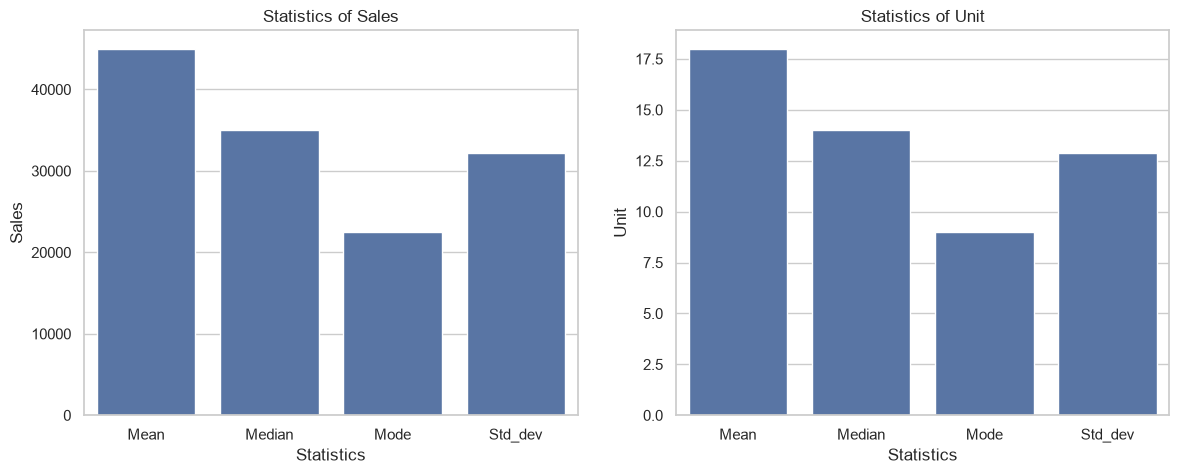


Summary Statistics: 

           Sales     Unit
count   7,560.00 7,560.00
mean   45,013.56    18.01
std    32,253.51    12.90
min     5,000.00     2.00
25%    20,000.00     8.00
50%    35,000.00    14.00
75%    65,000.00    26.00
max   162,500.00    65.00


In [147]:
# Mean, Median, Mode and Standard Deviation of Sales and Unit

Stats = {}                                                        # dictionary: statistic name -> [Sales value, Unit value]
Stats['Mean'] = [np.mean(df['Sales']), np.mean(df['Unit'])]
Stats['Median'] = [np.median(df['Sales']), np.median(df['Unit'])]
Stats['Mode'] = [statistics.mode(df['Sales']), statistics.mode(df['Unit'])]
Stats['Std_dev'] = [np.std(df['Sales'], ddof=1), np.std(df['Unit'], ddof=1)]
Stats_Table = pd.DataFrame(Stats, index=['Sales', 'Unit'])       # turn the dictionary into a table
print("\nStatistics of Sales and Unit : \n\n", Stats_Table.round(2))

print("\n Descriptive plot view of Statistics of Sales and Unit:\n")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=Stats_Table.columns, y=Stats_Table.loc['Sales'], ax=axes[0])
axes[0].set_title("Statistics of Sales")
axes[0].set_xlabel("Statistics")
axes[0].set_ylabel("Sales")
sns.barplot(x=Stats_Table.columns, y=Stats_Table.loc['Unit'], ax=axes[1])
axes[1].set_title("Statistics of Unit")
axes[1].set_xlabel("Statistics")
axes[1].set_ylabel("Unit")
plt.show()

print("\nSummary Statistics: \n")
print(df[['Sales', 'Unit']].describe().to_string())



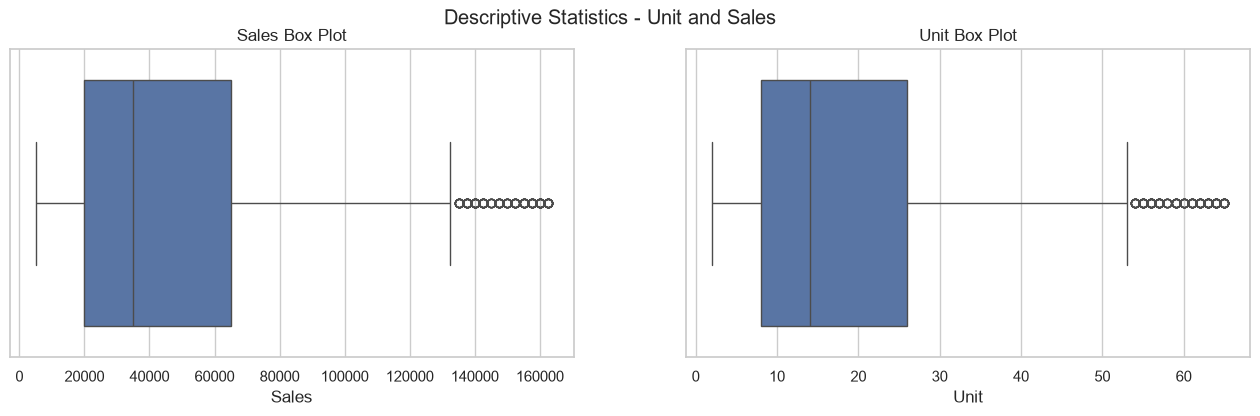

In [148]:
# Descriptive Analysis

# Box plot view of Sales and Unit

fig, axes = plt.subplots(1, 2, figsize=(16, 4)) 

sns.boxplot(x=df['Sales'], ax=axes[0])
axes[0].set_title("Sales Box Plot")
axes[0].set_xlabel("Sales")

sns.boxplot(x=df['Unit'], ax=axes[1])
axes[1].set_title("Unit Box Plot")
axes[1].set_xlabel("Unit")

fig.suptitle("Descriptive Statistics - Unit and Sales")
plt.show()

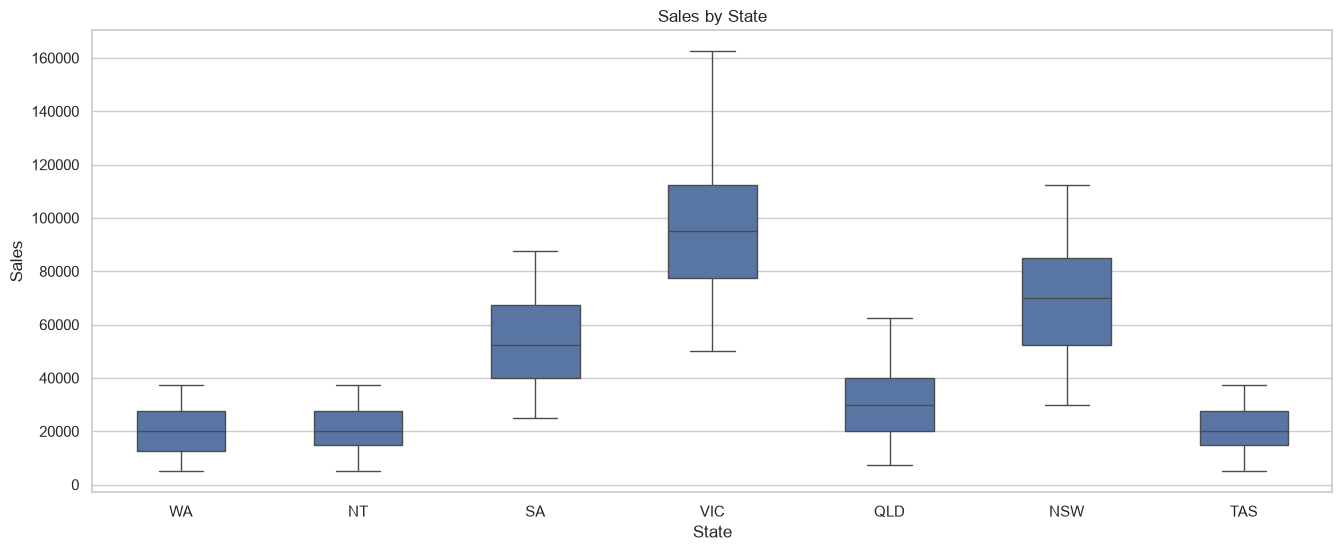

In [149]:
# Box plot of Sales for each State

plt.figure(figsize=(16, 6))
sns.boxplot(x='State', y='Sales', data=df, width=0.5)
plt.title("Sales by State")
plt.show()

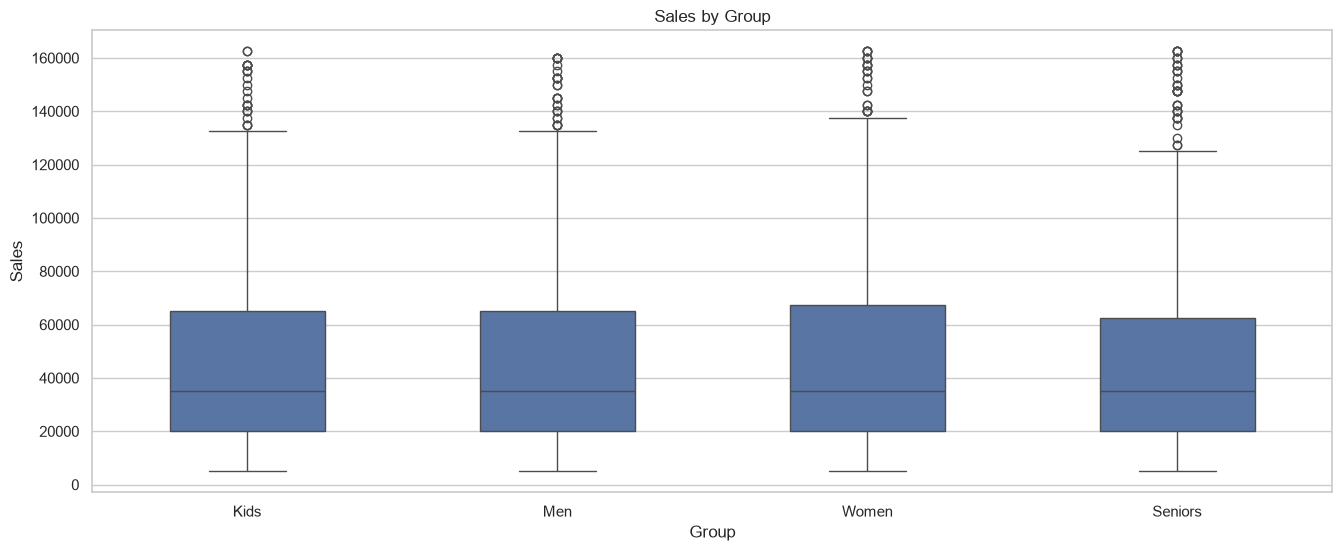

In [150]:
# Box plot of Sales for each Group

plt.figure(figsize=(16, 6))
sns.boxplot(x='Group', y='Sales', data=df, width=0.5)
plt.title("Sales by Group")
plt.show()

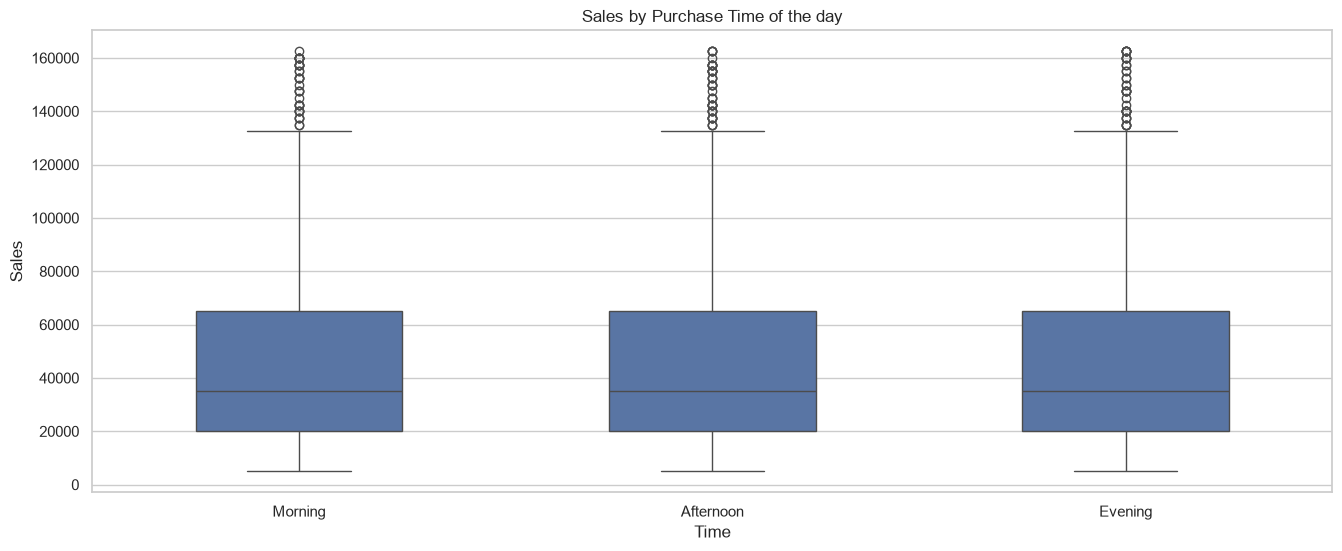

In [151]:
# Box plot of Sales for purchase time of the day

plt.figure(figsize=(16, 6))
sns.boxplot(x='Time', y='Sales', data=df, width=0.5)
plt.title("Sales by Purchase Time of the day")
plt.show()

Observation

- From the Descriptive Statistics and Box plot, the following is identified:
    - Sales Data : 
        - Mean of Sales 45,013.56
        - Median of Sales 35,000.00
        - Mode of Sales 22,500.00
        - Standard Deviation of Sales 32,253.51
    - Unit Data : 
        - Mean of Unit 18.01
        - Median of Unit 14.00
        - Mode of Unit 9.00
        - Standard Deviation of Unit 12.90
- For both columns Mean is more than Median and Median is more than Mode, which indicates most of the rows have small Sales value and few big sales make the average up. The dots on the higher end for sales / unit plot indicates this few big sales.
- From the box plot by State, VIC has the highest box and the longest whisker, WA, NT and TAS have the lowest boxes. The dots in the Group and Time box plots are the VIC rows

2.b Identify the group with the highest sales and the group with the lowest sales

In [152]:
# Function to convert big number to readable format (Billion / Million / Thousand)

def readable_number(value):                         
   sign = "-" if value < 0 else ""                  # keep the minus sign for negative values
   value = abs(value)
   if value >= 1000000000:
       return sign + str(round(value / 1000000000, 2)) + " Billion"
   elif value >= 1000000:
       return sign + str(round(value / 1000000, 2)) + " Million"
   elif value >= 1000:
       return sign + str(round(value / 1000, 2)) + " Thousand"
   else:
       return sign + str(round(value, 2))

In [153]:

# using groupby to calculate the total Unit and Sales for each Group

Group_Report = df.groupby('Group')[['Unit', 'Sales']].sum().sort_values('Sales', ascending=False)
Group_Report['Sales_Conv'] = Group_Report['Sales'].map(readable_number)                     # Sales in readable format
Group_Report['Share_Percentage'] = (Group_Report['Sales'] / Group_Report['Sales'].sum() * 100).round(2)  # share of total sales
print(Group_Report.to_string())

Highest_Sales_Group = Group_Report['Sales'].max()                                   # highest sales value
Lowest_Sales_Group = Group_Report['Sales'].min()                                    # lowest sales value
Highest_Group = Group_Report[Group_Report['Sales'] == Highest_Sales_Group].index[0] # group name with highest sales
Lowest_Group = Group_Report[Group_Report['Sales'] == Lowest_Sales_Group].index[0]   # group name with lowest sales

print("\nGroup with HIGHEST Sales : ", Highest_Group, "-", readable_number(Highest_Sales_Group))
print("Group with LOWEST Sales  : ", Lowest_Group, "-", readable_number(Lowest_Sales_Group))
print("Difference between highest and lowest group : ", readable_number(Highest_Sales_Group - Lowest_Sales_Group))
print("Difference between highest and lowest group (%) : ", round((Highest_Sales_Group - Lowest_Sales_Group) / Lowest_Sales_Group * 100, 2))

          Unit     Sales     Sales_Conv  Share_Percentage
Group                                                    
Men      34300  85750000  85.75 Million             25.20
Women    34177  85442500  85.44 Million             25.11
Kids     34029  85072500  85.07 Million             25.00
Seniors  33615  84037500  84.04 Million             24.69

Group with HIGHEST Sales :  Men - 85.75 Million
Group with LOWEST Sales  :  Seniors - 84.04 Million
Difference between highest and lowest group :  1.71 Million
Difference between highest and lowest group (%) :  2.04


Observation

- Group wise sales is calculated and is observed that Men contribute the highest sales - 85.75 million and Seniors contribute the lowest sales - 84.04 million
- The difference between the highest and the lowest group is only 2.04%, all four groups are very close to each other
- Each group contributes close to 25% of share

In summary, All groups contribute a fair share; sales are balanced across groups.

2.c Identify the state with the highest and lowest sales

In 2.b it is identified that Men Group contributes highest sales and Seniors Group contributes lowest sales.

The next potential category to check sales contribution is with "State" value

In [154]:
# using groupby to calculate the total Unit and Sales for each State

State_Report = df.groupby('State')[['Unit', 'Sales']].sum().sort_values('Sales', ascending=False)
State_Report['Sales_Conv'] = State_Report['Sales'].map(readable_number)                       # Sales in readable format
State_Report['Share_Percentage'] = (State_Report['Sales'] / State_Report['Sales'].sum() * 100).round(2)  # share of total sales
State_Order = list(State_Report.index)
print(State_Report.to_string())

Highest_State_Sales = State_Report['Sales'].max()                                        # highest sales value
Lowest_State_Sales = State_Report['Sales'].min()                                         # lowest sales value
Highest_State_Group = State_Report[State_Report['Sales'] == Highest_State_Sales].index[0]      # state name with highest sales
Lowest_State_Group = State_Report[State_Report['Sales'] == Lowest_State_Sales].index[0]        # state name with lowest sales

print("\nState with HIGHEST Sales : ", Highest_State_Group, "-", readable_number(Highest_State_Sales))
print("State with LOWEST Sales  : ", Lowest_State_Group, "-", readable_number(Lowest_State_Sales))
print("Highest state sales compared to the lowest (times) : ", (Highest_State_Sales/Lowest_State_Sales).round(2))
print("Difference between highest and lowest state : ", readable_number(Highest_State_Sales - Lowest_State_Sales))
print("Difference between highest and lowest state (%) : ", round((Highest_State_Sales - Lowest_State_Sales) / Lowest_State_Sales * 100, 2))
print("VIC + NSW + SA share of total sales (%) : ", round(State_Report.loc[['VIC', 'NSW', 'SA'], 'Sales'].sum() / State_Report['Sales'].sum() * 100, 2))

        Unit      Sales      Sales_Conv  Share_Percentage
State                                                    
VIC    42226  105565000  105.56 Million             31.02
NSW    29988   74970000   74.97 Million             22.03
SA     23543   58857500   58.86 Million             17.30
QLD    13367   33417500   33.42 Million              9.82
TAS     9104   22760000   22.76 Million              6.69
NT      9032   22580000   22.58 Million              6.64
WA      8861   22152500   22.15 Million              6.51

State with HIGHEST Sales :  VIC - 105.56 Million
State with LOWEST Sales  :  WA - 22.15 Million
Highest state sales compared to the lowest (times) :  4.77
Difference between highest and lowest state :  83.41 Million
Difference between highest and lowest state (%) :  376.54
VIC + NSW + SA share of total sales (%) :  70.35


Observation

- From the State wise sales, the following is identified:
    - Highest sales state
        - VIC 105.56 million
        - NSW 74.97 million
        - SA 58.86 million 
        - Three states combined contribute to 70.35% of the sales
    - Lowest sales states
        - WA 22.15 million
        - NT 22.58 million
        - TAS 22.76 million
- QLD 33.42 million is in the middle
- Highest sales state sells 4.77 times the lowest sales state

In summary, 
 - VIC is the highest sales state
 - WA is the lowest sales state group
 - High Revenue States - VIC, NSW and SA
 - Low Revenue States -  WA, NT and TAS
 - QLD is the middle state

2.d Generate weekly, monthly, and quarterly reports and analyze

2.d.1 Weekly Report

Week 1 starts on the first date of the data (1 Oct 2020) and every week is a block of 7 days, so all the weeks have equal length for Q4. Total number of actual days in Q4 is 92, excluding 2 missing days, total number of week should come 13


 Total Number of days in Q4 : 92

 Q4 Start Date :  2020-10-01 
 Q4 End Date :  2020-12-30

 Number of days from dataset : 90

 Missing dates from the dataset : 2

 Week number Calculated from the start date of Q4, consider 7 day week, and added to dataset

WEEKLY REPORT : 

 Week Start_Date   End_Date  Days  Unit    Sales  Sales_in_Millions  Sales_per_Day_in_Millions
    1 2020-10-01 2020-10-07     7 10632 26580000              26.58                       3.80
    2 2020-10-08 2020-10-14     7 10828 27070000              27.07                       3.87
    3 2020-10-15 2020-10-21     7 10631 26577500              26.58                       3.80
    4 2020-10-22 2020-10-28     7 10575 26437500              26.44                       3.78
    5 2020-10-29 2020-11-04     6  7756 19390000              19.39                       3.23
    6 2020-11-05 2020-11-11     7  8364 20910000              20.91                       2.99
    7 2020-11-12 2020-11-18     7  8618 21545000          

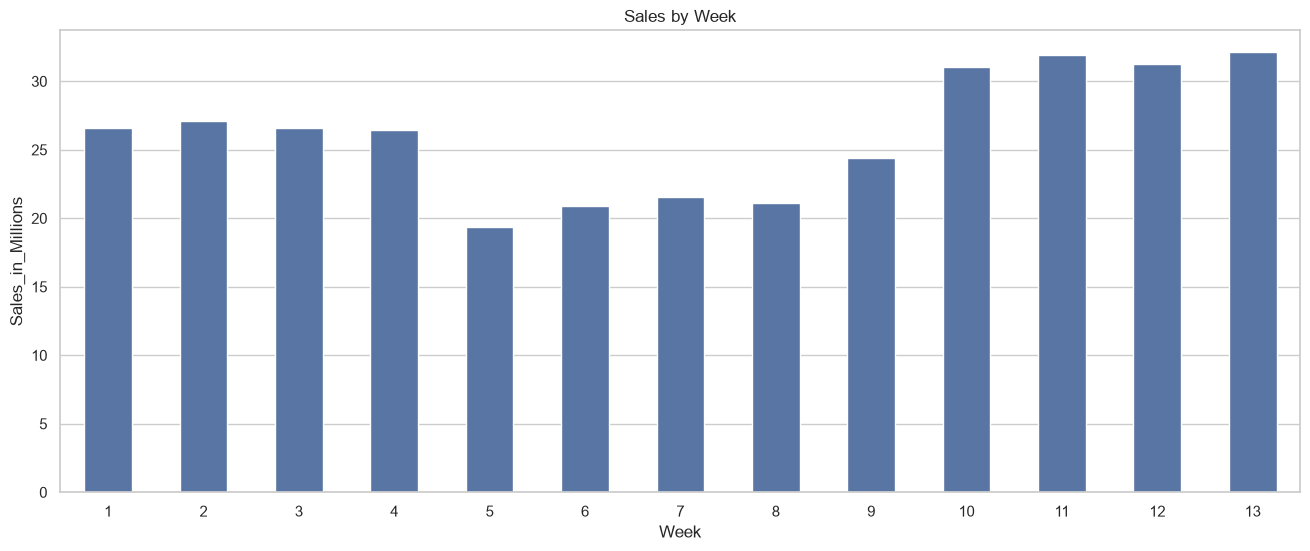

In [155]:
# Number of days in Q4

print("\n Total Number of days in Q4 :", len(Q4_days))
print("\n Q4 Start Date : ", df['Date'].min().date(), "\n Q4 End Date : ", df['Date'].max().date())
print("\n Number of days from dataset :", df['Date'].nunique())
print("\n Missing dates from the dataset :", len(Q4_days)-df['Date'].nunique())

# Consider 7 day week, starting from the start date of Q4, Week number is assigned for the dataset

df['Week'] = (df['Date'] - df['Date'].min()).dt.days // 7 + 1 # Difference of current date and start date of Q4, use floor to calculate week number

print("\n Week number Calculated from the start date of Q4, consider 7 day week, and added to dataset")

Weekly_Report = df.groupby('Week').agg({'Date': ['min', 'max', 'nunique'], 'Unit': 'sum', 'Sales': 'sum'}).reset_index() 
Weekly_Report.columns = ['Week', 'Start_Date', 'End_Date', 'Days', 'Unit', 'Sales']
Weekly_Report['Sales_in_Millions'] = Weekly_Report['Sales'] / 1000000
Weekly_Report['Sales_per_Day_in_Millions'] = Weekly_Report['Sales_in_Millions'] / Weekly_Report['Days']
print("\nWEEKLY REPORT : \n")
print(Weekly_Report.to_string(index=False))

# Weekly sales of every State (in millions)

Weekly_State = df.pivot_table(index='Week', columns='State', values='Sales', aggfunc='sum') / 1000000
Weekly_State = Weekly_State[State_Order]
print("\nWEEKLY REPORT - State wise (Sales in millions) : \n")
print(Weekly_State.to_string())

# Bar plot of Sales in Millions per Week

plt.figure(figsize=(16, 6)) 
sns.barplot(x=Weekly_Report['Week'], y=Weekly_Report['Sales_in_Millions'], data=df, width=0.5)
plt.title("Sales by Week")
plt.show()

Observation

- From the Weekly report, 
    - Week 1 to 4 are steady at around 26 million per week
    - Sales drop in week 5, which has only 6 days
    - Weeks 5 to 8 together average 20 million per week
    - Sales then increase from week 9 and Weeks 10 to 13 are the best sales weeks with an average around 30 million, the highest is week 13 with 32.12 million


2.d.2 Monthly report


 Month number and Month name taken from the Date column, and added to dataset

MONTHLY REPORT : 

 Month Month_Name Start_Date   End_Date  Days  Unit     Sales  Sales_in_Millions  Sales_per_Day_in_Millions
    10    October 2020-10-01 2020-10-30    30 45716 114290000             114.29                       3.81
    11   November 2020-11-01 2020-11-30    30 36273  90682500              90.68                       3.02
    12   December 2020-12-01 2020-12-30    30 54132 135330000             135.33                       4.51

MONTHLY REPORT - State wise Sales in millions : 

State        VIC   NSW    SA   QLD  TAS   NT   WA
Month_Name                                       
October    33.44 25.01 20.61 11.12 8.02 8.22 7.87
November   29.53 21.49 15.53  8.11 5.54 5.26 5.22
December   42.59 28.47 22.71 14.19 9.20 9.10 9.06


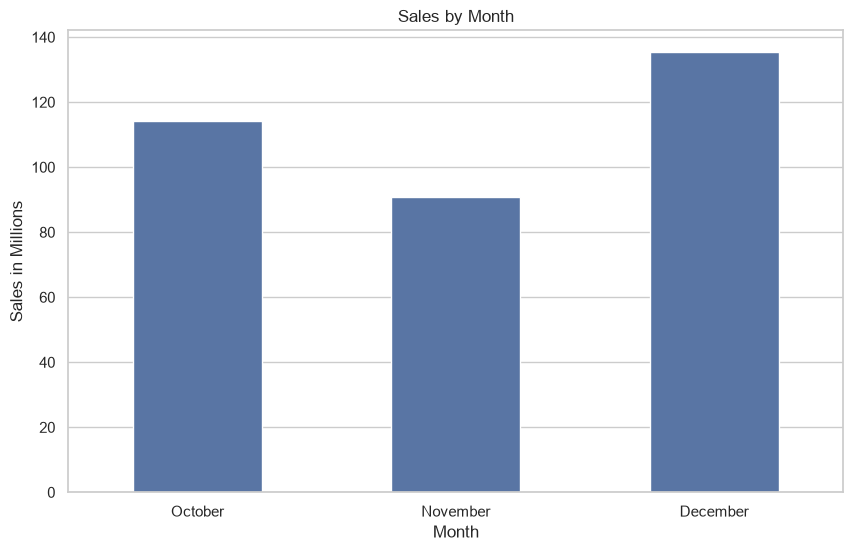


December vs November sales change (%) :  49.23


In [156]:
# Month number and name are taken from the Date column

df['Month'] = df['Date'].dt.month                                                   # 10, 11, 12
df['Month_Name'] = df['Month'].map({10: 'October', 11: 'November', 12: 'December'}) # month name for reports

print("\n Month number and Month name taken from the Date column, and added to dataset")

Monthly_Report = df.groupby(['Month', 'Month_Name']).agg({'Date': ['min', 'max', 'nunique'], 'Unit': 'sum', 'Sales': 'sum'}).reset_index()
Monthly_Report.columns = ['Month', 'Month_Name', 'Start_Date', 'End_Date', 'Days', 'Unit', 'Sales']
Monthly_Report['Sales_in_Millions'] = Monthly_Report['Sales'] / 1000000
Monthly_Report['Sales_per_Day_in_Millions'] = Monthly_Report['Sales_in_Millions'] / Monthly_Report['Days']
print("\nMONTHLY REPORT : \n")
print(Monthly_Report.to_string(index=False))

# Monthly sales of every State in millions

Monthly_State = df.pivot_table(index='Month_Name', columns='State', values='Sales', aggfunc='sum') / 1000000
Monthly_State = Monthly_State.loc[['October', 'November', 'December'], State_Order]   # month order and state order
print("\nMONTHLY REPORT - State wise Sales in millions : \n")
print(Monthly_State.to_string())

# Bar plot of Sales in Millions per Month

plt.figure(figsize=(10, 6))
sns.barplot(x='Month_Name', y='Sales_in_Millions', data=Monthly_Report, width=0.5)
plt.title("Sales by Month")
plt.xlabel("Month")
plt.ylabel("Sales in Millions")
plt.show()
print("\nDecember vs November sales change (%) : ", round((Monthly_Report.loc[Monthly_Report['Month'] == 12, 'Sales'].iloc[0] / Monthly_Report.loc[Monthly_Report['Month'] == 11, 'Sales'].iloc[0] - 1) * 100, 2))

Observation

- From the monthly report,
    - October had steady sales of 114.29 million
    - November sales dropped to 90.68 million
    - December sales improved and hit the highest with 135.33 million

2.d.3 Quarterly report

The dataset has only fourth quarter, so quarterly report is the total of Q4 2020


 Quarter number and Quarter name taken from the Month column, and added to dataset

QUARTERLY REPORT : 

 Quarter Quarter_Name Start_Date   End_Date  Days   Unit     Sales  Sales_in_Millions  Sales_per_Day_in_Millions
       4           Q4 2020-10-01 2020-12-30    90 136121 340302500             340.30                       3.78

QUARTERLY REPORT - State wise (Sales in millions) : 

Quarter_Name     Q4  Share_Percentage
State                                
VIC          105.56             31.02
NSW           74.97             22.03
SA            58.86             17.30
QLD           33.42              9.82
TAS           22.76              6.69
NT            22.58              6.64
WA            22.15              6.51


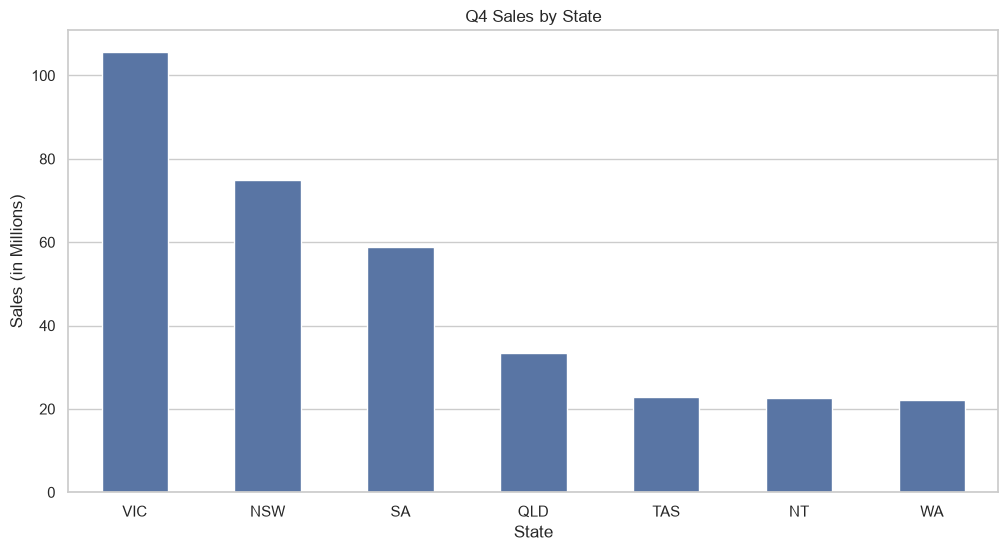

In [157]:
# Quarter number is taken from the Month (Oct, Nov, Dec = Quarter 4)

df['Quarter'] = (df['Month'] - 1) // 3 + 1                                          # months 10-12 give 4
df['Quarter_Name'] = "Q" + df['Quarter'].astype(str)                                # Q4

print("\n Quarter number and Quarter name taken from the Month column, and added to dataset")

Quarterly_Report = df.groupby(['Quarter', 'Quarter_Name']).agg({'Date': ['min', 'max', 'nunique'], 'Unit': 'sum', 'Sales': 'sum'}).reset_index()
Quarterly_Report.columns = ['Quarter', 'Quarter_Name', 'Start_Date', 'End_Date', 'Days', 'Unit', 'Sales']
Quarterly_Report['Sales_in_Millions'] = Quarterly_Report['Sales'] / 1000000
Quarterly_Report['Sales_per_Day_in_Millions'] = Quarterly_Report['Sales_in_Millions'] / Quarterly_Report['Days']
print("\nQUARTERLY REPORT : \n")
print(Quarterly_Report.to_string(index=False))

# Quarterly sales of every State (in millions) with share of total

Quarterly_State = df.pivot_table(index='State', columns='Quarter_Name', values='Sales', aggfunc='sum') / 1000000
Quarterly_State = Quarterly_State.loc[State_Order]                                  # state order
Quarterly_State['Share_Percentage'] = (Quarterly_State['Q4'] / Quarterly_State['Q4'].sum() * 100).round(2)
print("\nQUARTERLY REPORT - State wise (Sales in millions) : \n")
print(Quarterly_State.to_string())

# Bar plot of Q4 Sales in Millions per State

plt.figure(figsize=(12, 6))
sns.barplot(x=Quarterly_State.index, y=Quarterly_State['Q4'], width=0.5)
plt.title("Q4 Sales by State")
plt.xlabel("State")
plt.ylabel("Sales (in Millions)")
plt.show()

Observation

- From the Quarterly report, 
    - Q4 2020 total sales is 340.30 million from 136,121 units
    - Highest Share % has come from VIC state

STEP3 : DATA VISUALIZATION

3.a Dashboard - State-wise, Group-wise and Time of day sales

3.a.1 To construct a dashboard for the head of sales and marketing, encompassing key parameters State-wise sales, Group-wise sales, Time of day analysis

3.a.1.1 State-wise sales analysis for different demographic groups (Kids, Women, Men and Seniors)


 State vs Group Sales in millions : 

Group  Kids  Women   Men  Seniors
State                            
VIC   26.36  26.48 26.41    26.32
NSW   18.59  19.17 19.02    18.19
SA    14.52  14.97 14.65    14.72
QLD    8.51   8.32  8.39     8.19
TAS    5.78   5.58  5.76     5.65
NT     5.70   5.65  5.76     5.46
WA     5.62   5.26  5.75     5.51

Highest and lowest Group inside every State : 

VIC : 
 highest sales -  Women 26.48 
 lowest sales -  Seniors 26.32 
 gap (%) -  0.64
NSW : 
 highest sales -  Women 19.17 
 lowest sales -  Seniors 18.19 
 gap (%) -  5.42
SA : 
 highest sales -  Women 14.97 
 lowest sales -  Kids 14.52 
 gap (%) -  3.13
QLD : 
 highest sales -  Kids 8.51 
 lowest sales -  Seniors 8.19 
 gap (%) -  3.91
TAS : 
 highest sales -  Kids 5.78 
 lowest sales -  Women 5.58 
 gap (%) -  3.54
NT : 
 highest sales -  Men 5.76 
 lowest sales -  Seniors 5.46 
 gap (%) -  5.44
WA : 
 highest sales -  Men 5.75 
 lowest sales -  Women 5.26 
 gap (%) -  9.31


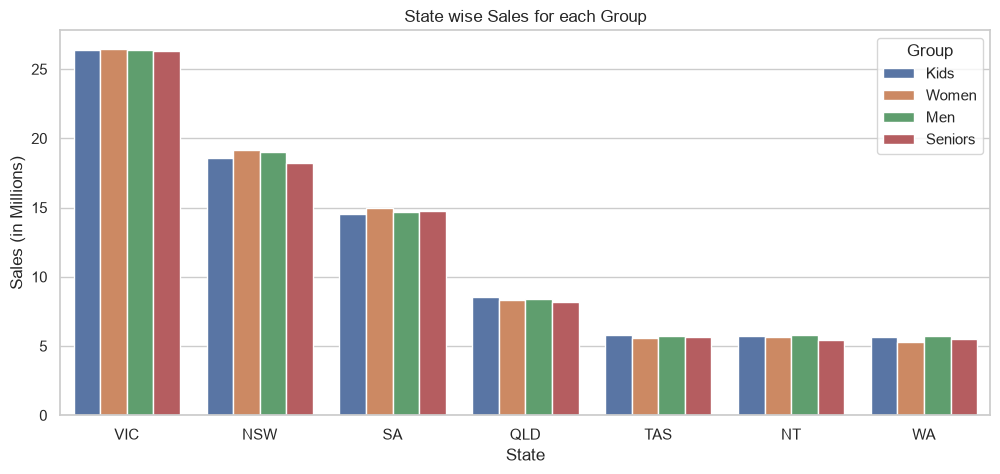

In [158]:
# State and Group total sales in millions, the states are in the order of highest to lowest sales (State_Order)

State_Group_Millions = df.pivot_table(index='State', columns='Group', values='Sales', aggfunc='sum') / 1000000
State_Group_Millions = State_Group_Millions.loc[State_Order, ['Kids', 'Women', 'Men', 'Seniors']]
print("\n State vs Group Sales in millions : \n")
print(State_Group_Millions.to_string())

# Highest and lowest Group inside every State

print("\nHighest and lowest Group inside every State : \n")
for s in State_Order:
    r = State_Group_Millions.loc[s].sort_values(ascending=False)
    print(s, ": \n highest sales - ", r.index[0], round(r.iloc[0], 2), "\n lowest sales - ", r.index[-1], round(r.iloc[-1], 2), "\n gap (%) - ", round((r.iloc[0] - r.iloc[-1]) / r.iloc[-1] * 100, 2))

# same data in long format (one row for each State and Group) for the bar plot

State_Group_Sales = df.groupby(['State', 'Group'])['Sales'].sum().reset_index()
State_Group_Sales['Sales_in_Millions'] = State_Group_Sales['Sales'] / 1000000

plt.figure(figsize=(12, 5))
sns.barplot(x='State', y='Sales_in_Millions', hue='Group', data=State_Group_Sales, order=State_Order, hue_order=['Kids', 'Women', 'Men', 'Seniors'])
plt.xlabel("State")
plt.ylabel("Sales (in Millions)")
plt.title("State wise Sales for each Group")
plt.show()

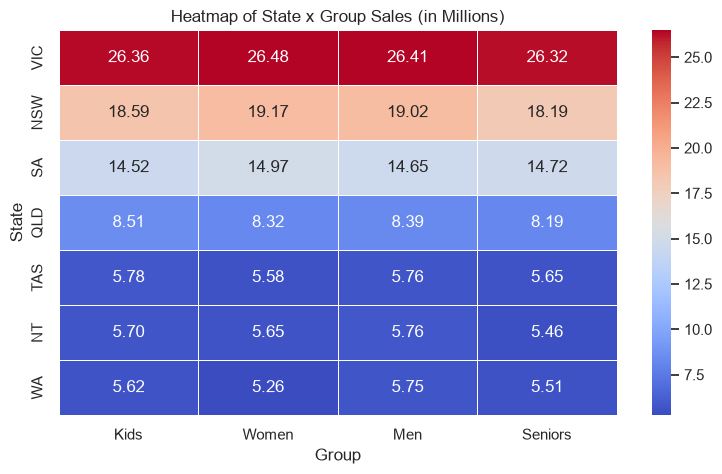

In [159]:
# Heatmap view of State x Group sales

plt.figure(figsize=(9,5))
sns.heatmap(State_Group_Millions, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.xlabel("Group")
plt.ylabel("State")
plt.title("Heatmap of State x Group Sales (in Millions)")
plt.show()

Observation

- From the Visualization of State wise sales for each group
    - Women are the top group in VIC with 26.48 Million, NSW with 19.17 million and SA with 14.97 million
    - Seniors are the lowest group in 4 states - VIC, NSW, QLD and NT
    - The biggest gap between the highest and the lowest group is in WA  with 9.31%

In summary, the state decides the sales level more than the group. The four groups are balanced in every state, and the low revenue states are low for all the groups

3.a.1.2 Group-wise sales analysis (Kids, Women, Men and Seniors) across various states


 Share of every State inside each Group (%) : 

State     VIC   NSW    SA   QLD  TAS   NT   WA
Group                                         
Kids    30.99 21.85 17.06 10.00 6.79 6.70 6.61
Women   30.99 22.44 17.52  9.74 6.53 6.62 6.16
Men     30.80 22.18 17.09  9.79 6.71 6.72 6.71
Seniors 31.31 21.64 17.51  9.75 6.72 6.50 6.56

 WA + NT + TAS share inside each Group (%) : 

Group
Kids      20.10
Women     19.30
Men       20.14
Seniors   19.79


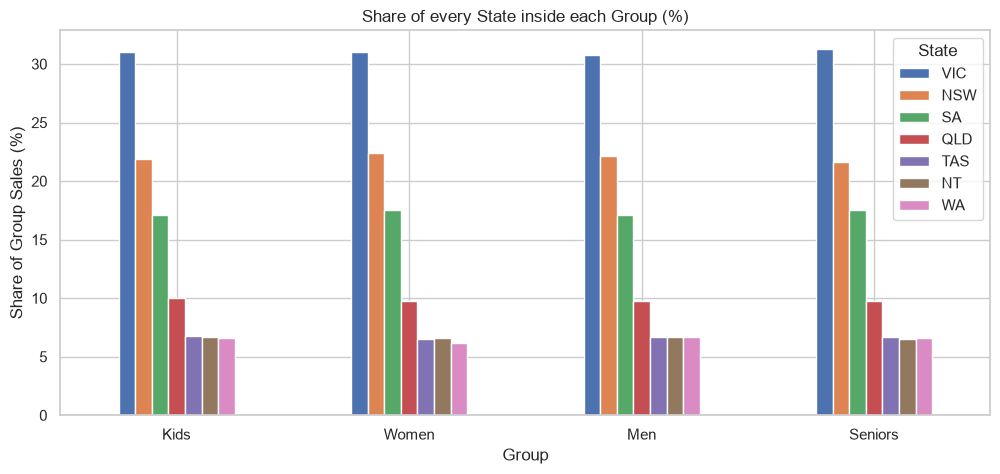

In [160]:
# Share of every State inside each Group (%)

State_Group_Share = State_Group_Millions / State_Group_Millions.sum() * 100
print("\n Share of every State inside each Group (%) : \n")
print(State_Group_Share.T.to_string())
print("\n WA + NT + TAS share inside each Group (%) : \n")
print(State_Group_Share.loc[['WA', 'NT', 'TAS']].sum().round(2).to_string())


State_Group_Share.T.plot(kind='bar', figsize=(12, 5))
plt.xlabel("Group")
plt.ylabel("Share of Group Sales (%)")
plt.title("Share of every State inside each Group (%)")
plt.xticks(rotation=0)
plt.legend(title="State")
plt.show()

Observation

- From the Visualization of group wise sales across states,
    - VIC, NSW, SA and QLD are in the same order in all four groups, and WA, NT and TAS are the bottom three in every group
    - VIC share is around 31% for each group (30.80% to 31.31%) and WA, NT and TAS together make only 19.30% to 20.14%

In summary, each group depends on the same three high revenue states (VIC, NSW, SA). There is no strong group in low revenue states

3.a.1.3 Time-of-the-day analysis


Time of the day Report : 

            Unit      Sales      Sales_Conv  Sales_in_Millions  Share_Percentage
Time                                                                            
Morning    45683  114207500  114.21 Million             114.21             33.56
Afternoon  45603  114007500  114.01 Million             114.01             33.50
Evening    44835  112087500  112.09 Million             112.09             32.94

 PEAK time :  Morning 
 OFF-PEAK time :  Evening
Gap between peak and off-peak (%) :  1.89


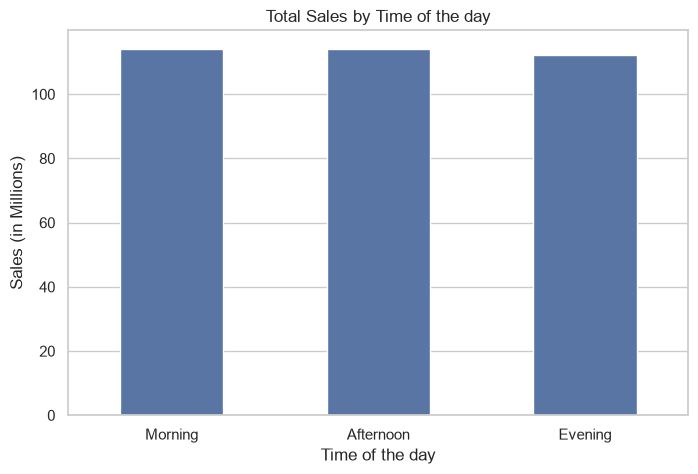

In [161]:
# Total sales for Time of the day

Time_Report = df.groupby('Time')[['Unit', 'Sales']].sum().sort_values('Sales', ascending=False)
Time_Report['Sales_Conv'] = Time_Report['Sales'].map(readable_number)                          # Sales in readable format
Time_Report['Sales_in_Millions'] = Time_Report['Sales'] / 1000000
Time_Report['Share_Percentage'] = (Time_Report['Sales'] / Time_Report['Sales'].sum() * 100).round(2)  # share of total sales
print("\nTime of the day Report : \n")
print(Time_Report.to_string())
print("\n PEAK time : ", Time_Report.index[0],
      "\n OFF-PEAK time : ", Time_Report.index[-1])
print("Gap between peak and off-peak (%) : ", round((Time_Report['Sales'].iloc[0] - Time_Report['Sales'].iloc[-1]) / Time_Report['Sales'].iloc[-1] * 100, 2))

plt.figure(figsize=(8, 5))
sns.barplot(x=Time_Report.index, y=Time_Report['Sales_in_Millions'], width=0.5)
plt.xlabel("Time of the day")
plt.ylabel("Sales (in Millions)")
plt.title("Total Sales by Time of the day")
plt.show()

In [162]:
# Peak and off-peak time inside every State

Time_State = df.pivot_table(index='State', columns='Time', values='Sales', aggfunc='sum') / 1000000
Time_State = Time_State.loc[State_Order, ['Morning', 'Afternoon', 'Evening']]
Peak_Rows = []
for s in State_Order:
    r = Time_State.loc[s].sort_values(ascending=False)
    Peak_Rows.append([s, r.index[0], r.iloc[0], r.index[-1], r.iloc[-1], (r.iloc[0] - r.iloc[-1]) / r.iloc[-1] * 100])
Peak_State = pd.DataFrame(Peak_Rows, columns=['State', 'Peak_Time', 'Peak_Sales_M', 'OffPeak_Time', 'OffPeak_Sales_M', 'Gap_Pct'])
print("\nPeak and off-peak time for every State : \n")
print(Peak_State.to_string(index=False))

# Peak and off-peak time inside every Group

Time_Group = df.pivot_table(index='Group', columns='Time', values='Sales', aggfunc='sum') / 1000000
Peak_Rows = []
for g in ['Kids', 'Women', 'Men', 'Seniors']:
    r = Time_Group.loc[g].sort_values(ascending=False)
    Peak_Rows.append([g, r.index[0], r.iloc[0], r.index[-1], r.iloc[-1], (r.iloc[0] - r.iloc[-1]) / r.iloc[-1] * 100])
Peak_Group = pd.DataFrame(Peak_Rows, columns=['Group', 'Peak_Time', 'Peak_Sales_M', 'OffPeak_Time', 'OffPeak_Sales_M', 'Gap_Pct'])
print("\nPeak and off-peak time for every Group : \n")
print(Peak_Group.to_string(index=False))


Peak and off-peak time for every State : 

State Peak_Time  Peak_Sales_M OffPeak_Time  OffPeak_Sales_M  Gap_Pct
  VIC   Morning         35.62      Evening            34.88     2.13
  NSW   Morning         25.15      Evening            24.71     1.76
   SA Afternoon         20.02      Evening            19.37     3.39
  QLD   Morning         11.44      Evening            10.63     7.57
  TAS Afternoon          7.67      Morning             7.53     1.93
   NT   Evening          7.63      Morning             7.44     2.49
   WA   Morning          7.57    Afternoon             7.28     3.91

Peak and off-peak time for every Group : 

  Group Peak_Time  Peak_Sales_M OffPeak_Time  OffPeak_Sales_M  Gap_Pct
   Kids   Morning         28.52      Evening            28.05     1.66
  Women   Evening         28.55      Morning            28.36     0.67
    Men Afternoon         28.77      Evening            28.22     1.93
Seniors   Morning         28.57      Evening            27.27     4.80


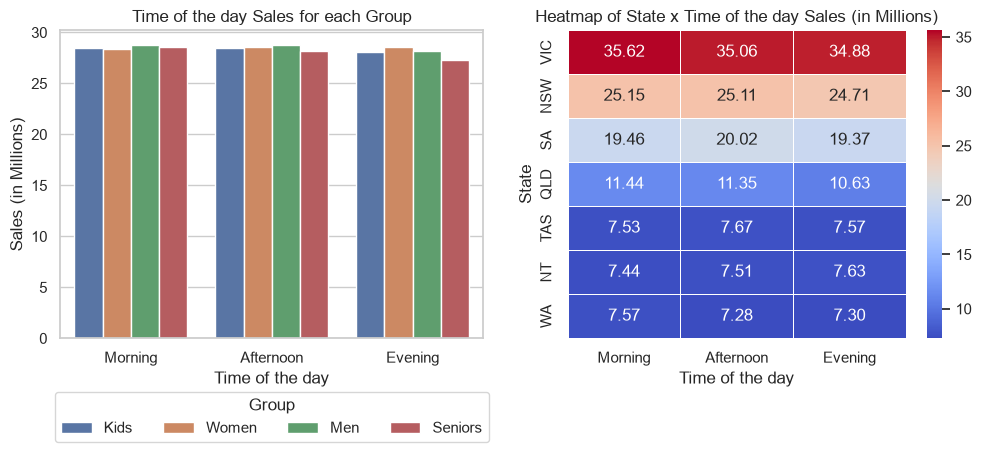

In [163]:
# Time of the day sales for each Group and for each State

Time_Group_Sales = df.groupby(['Group', 'Time'])['Sales'].sum().reset_index()
Time_Group_Sales['Sales_in_Millions'] = Time_Group_Sales['Sales'] / 1000000

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(x='Time', y='Sales_in_Millions', hue='Group', data=Time_Group_Sales, order=['Morning', 'Afternoon', 'Evening'], hue_order=['Kids', 'Women', 'Men', 'Seniors'], ax=axes[0])
axes[0].set_title("Time of the day Sales for each Group")
axes[0].set_xlabel("Time of the day")
axes[0].set_ylabel("Sales (in Millions)")
axes[0].legend(title="Group", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4)   # legend below the chart, so the bars are not hidden

sns.heatmap(Time_State, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, ax=axes[1])
axes[1].set_title("Heatmap of State x Time of the day Sales (in Millions)")
axes[1].set_xlabel("Time of the day")
axes[1].set_ylabel("State")

plt.show()

Observation

- From the Visualization of time of the day sales,
    - Overall PEAK time is Morning and the OFF-PEAK time is Evening
    - The gap between peak and off-peak is only 1.89%, so the time of the day has a very small effect on the total sales

In summary, time of the day has a small effect at overall level, as the gap between peak and off-peak is minimal. It is recommended to introduce sales offer in off-peak time state-wise

3.b Visualization for decision making - the dashboard with daily, weekly, monthly and quarterly charts

3.b.1 Daily chart


Number of days :  90
Average daily sales :  3.78 Million

Top 5 days : 

      Date  Unit   Sales  Sales_in_Millions
2020-12-14  1906 4765000               4.76
2020-12-10  1887 4717500               4.72
2020-12-26  1886 4715000               4.71
2020-12-15  1863 4657500               4.66
2020-12-09  1862 4655000               4.66

Lowest 5 days (the earlier date is taken when the sales are same) : 

      Date  Unit   Sales  Sales_in_Millions
2020-11-02  1090 2725000               2.73
2020-11-06  1134 2835000               2.83
2020-11-22  1147 2867500               2.87
2020-11-11  1149 2872500               2.87
2020-11-03  1151 2877500               2.88


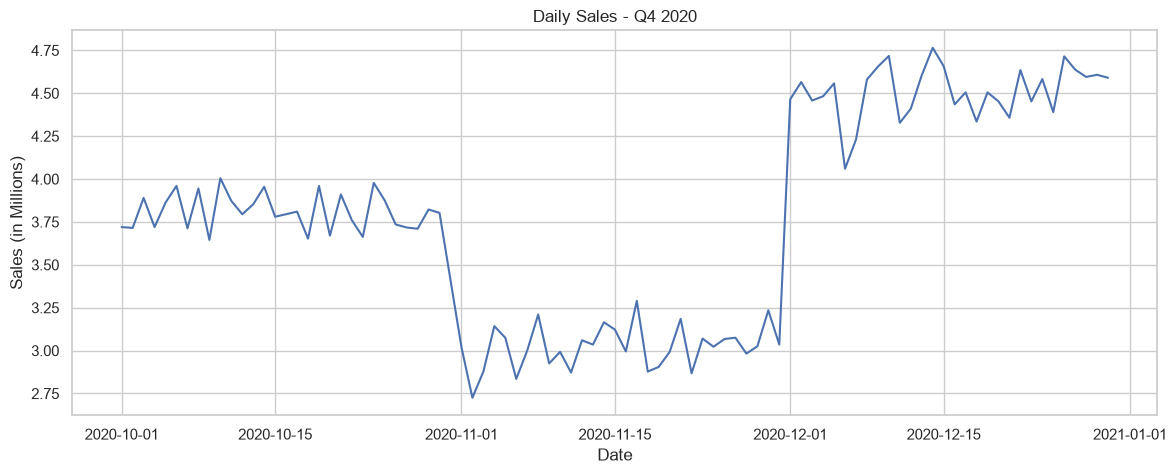

In [164]:
# Daily total sales in millions

Daily_Sales = df.groupby('Date')[['Unit', 'Sales']].sum().reset_index()
Daily_Sales['Sales_in_Millions'] = Daily_Sales['Sales'] / 1000000
print("\nNumber of days : ", len(Daily_Sales))
print("Average daily sales : ", readable_number(Daily_Sales['Sales'].mean()))
print("\nTop 5 days : \n")
print(Daily_Sales.sort_values(['Sales', 'Date'], ascending=[False, True]).head(5).to_string(index=False))
print("\nLowest 5 days (the earlier date is taken when the sales are same) : \n")
print(Daily_Sales.sort_values(['Sales', 'Date']).head(5).to_string(index=False))

plt.figure(figsize=(14, 5))
sns.lineplot(x='Date', y='Sales_in_Millions', data=Daily_Sales)
plt.xlabel("Date")
plt.ylabel("Sales (in Millions)")
plt.title("Daily Sales - Q4 2020")
plt.show()


Average daily sales for each day of the week : 

           Days     Sales  Sales_per_Day_in_Millions
Day_Name                                            
Monday       13  48050000                       3.70
Tuesday      13  50327500                       3.87
Wednesday    13  49945000                       3.84
Thursday     13  49405000                       3.80
Friday       13  48000000                       3.69
Saturday     12  46245000                       3.85
Sunday       13  48330000                       3.72


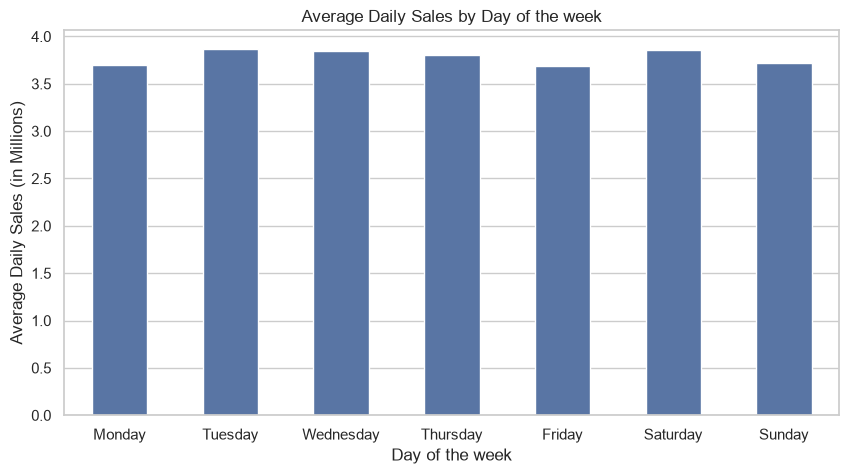

In [165]:
# Average daily sales for each day of the week, 

Day_Names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df['Day_Name'] = df['Date'].map(find_day)                                                       # day name is found with find_day function from previous section
Weekday_Report = df.groupby('Day_Name').agg({'Date': 'nunique', 'Sales': 'sum'})
Weekday_Report.columns = ['Days', 'Sales']
Weekday_Report = Weekday_Report.loc[Day_Names]                                           # Monday to Sunday order
Weekday_Report['Sales_per_Day_in_Millions'] = Weekday_Report['Sales'] / Weekday_Report['Days'] / 1000000
print("\nAverage daily sales for each day of the week : \n")
print(Weekday_Report.to_string())

plt.figure(figsize=(10, 5))
sns.barplot(x=Weekday_Report.index, y=Weekday_Report['Sales_per_Day_in_Millions'], width=0.5)
plt.xlabel("Day of the week")
plt.ylabel("Average Daily Sales (in Millions)")
plt.title("Average Daily Sales by Day of the week")
plt.show()

Observation

- From the Visualization of daily sales, 
    - Daily sales are 3.78 million on average. The highest day is 2020-12-14 with 4.76 million and the lowest day is 2020-11-02 with 2.73 million
    - The 5 best sales days are in December and the 5 lowest sales days are in November
    - Day of the week has only a small effect, Tuesday is the highest with 3.87 million per day and Friday the lowest with 3.69 million per day, the difference is small

In summary, the daily sales are mostly decided by the month and not by the day of the week

3.b.2 Weekly chart


Average weekly sales in millions :  
 Weeks 1 to 4   :  26.67 
 Weeks 5 to 8   :  20.74 
 Weeks 10 to 13 :  31.58


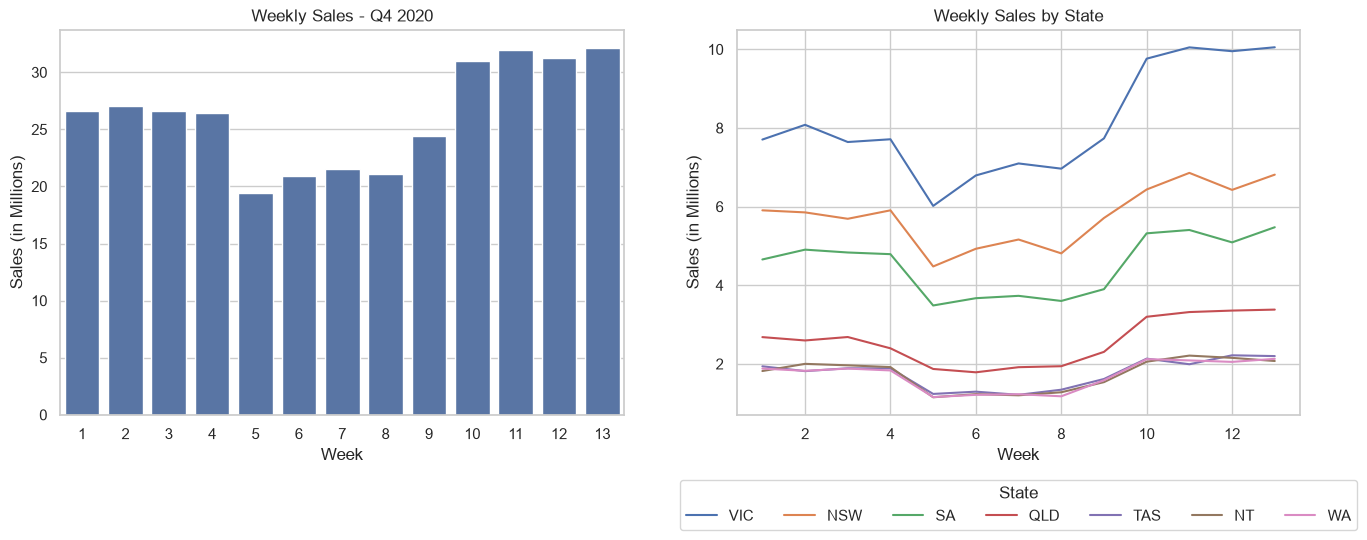

In [166]:
# Weekly total sales (Weekly_Report) and weekly sales of every State (Weekly_State) from section 2.d.1

print("\nAverage weekly sales in millions : ",
      "\n Weeks 1 to 4   : ", round(Weekly_Report.loc[Weekly_Report['Week'].between(1, 4), 'Sales_in_Millions'].mean(), 2),
      "\n Weeks 5 to 8   : ", round(Weekly_Report.loc[Weekly_Report['Week'].between(5, 8), 'Sales_in_Millions'].mean(), 2),
      "\n Weeks 10 to 13 : ", round(Weekly_Report.loc[Weekly_Report['Week'].between(10, 13), 'Sales_in_Millions'].mean(), 2))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(x='Week', y='Sales_in_Millions', data=Weekly_Report, ax=axes[0])
axes[0].set_title("Weekly Sales - Q4 2020")
axes[0].set_xlabel("Week")
axes[0].set_ylabel("Sales (in Millions)")

sns.lineplot(data=Weekly_State, dashes=False, ax=axes[1])                     # one line for each State column
axes[1].set_title("Weekly Sales by State")
axes[1].set_xlabel("Week")
axes[1].set_ylabel("Sales (in Millions)")
axes[1].legend(title="State", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=7)   # legend below the chart, so the lines are not hidden

plt.show()

Observation

- From the Visualization of weekly sales,
    - Weeks 1 to 4 are high and steady (26.67 million per week on average), week 5 is the lowest in total (19.39 million, only 6 days) and week 13 is the highest (32.12 million)
    - All the states follow the same shape, a fall in weeks 5 to 8 and a rise from week 9, so the November fall is not limited to one state. VIC and NSW are always on the top, and WA, NT and TAS always at the bottom

In summary, the sales have a clear weekly pattern (steady, low, high) which can be used for the planning of stock and promotions

3.b.3 Monthly chart


Monthly change of sales for every State (%) : 

       November_vs_October  December_vs_November
State                                           
VIC                 -11.70                 44.23
NSW                 -14.07                 32.49
SA                  -24.64                 46.24
QLD                 -27.07                 74.94
TAS                 -30.82                 65.92
NT                  -36.06                 73.09
WA                  -33.72                 73.69

VIC sales compared to WA (times) : 
  October : 4.25
  November : 5.66
  December : 4.7


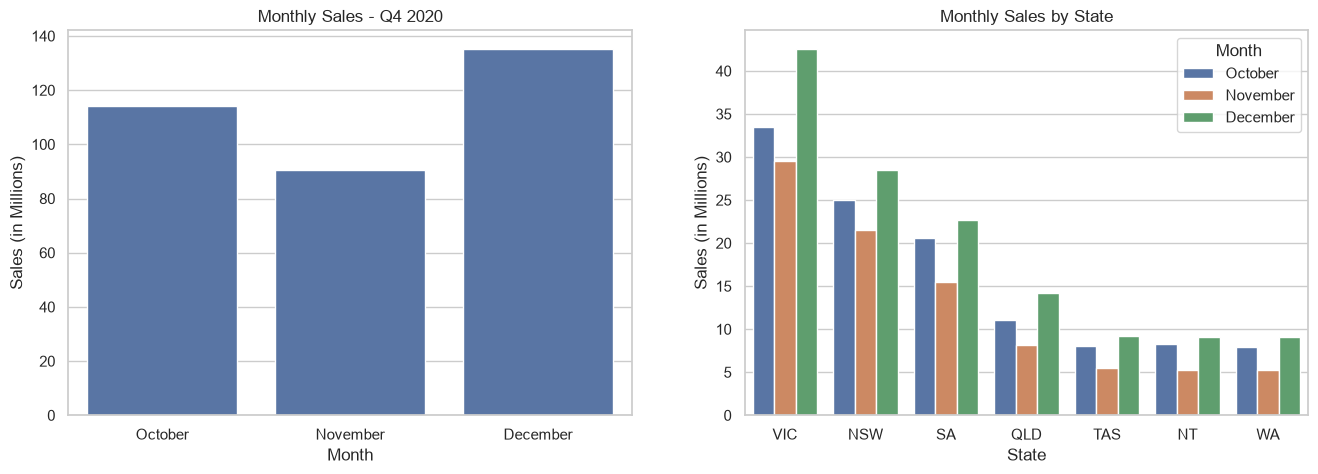

In [167]:
# Monthly change of sales for every State (%), from the Monthly_State table of section 2.d.2

Monthly_Change = pd.DataFrame({
    'November_vs_October': (Monthly_State.loc['November'] / Monthly_State.loc['October'] - 1) * 100,
    'December_vs_November': (Monthly_State.loc['December'] / Monthly_State.loc['November'] - 1) * 100})
print("\nMonthly change of sales for every State (%) : \n")
print(Monthly_Change.to_string())
print("\nVIC sales compared to WA (times) : ")
for m in ['October', 'November', 'December']:
    print(" ", m, ":", round(Monthly_State.loc[m, 'VIC'] / Monthly_State.loc[m, 'WA'], 2))

# monthly sales of every State in long format for the bar plot

Monthly_State_Sales = df.groupby(['Month', 'Month_Name', 'State'])['Sales'].sum().reset_index()
Monthly_State_Sales['Sales_in_Millions'] = Monthly_State_Sales['Sales'] / 1000000

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(x='Month_Name', y='Sales_in_Millions', data=Monthly_Report, ax=axes[0])
axes[0].set_title("Monthly Sales - Q4 2020")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Sales (in Millions)")

sns.barplot(x='State', y='Sales_in_Millions', hue='Month_Name', data=Monthly_State_Sales, order=State_Order, hue_order=['October', 'November', 'December'], ax=axes[1])
axes[1].set_title("Monthly Sales by State")
axes[1].set_xlabel("State")
axes[1].set_ylabel("Sales (in Millions)")
axes[1].legend(title="Month")

plt.show()

Conclusion

- From the Visualization of monthly sales,
    - December is the highest month (135.33 million), November the lowest (90.68 million) and October is in the middle (114.29 million). 
    - Every state follows the same pattern in sales (high, low, higher)
    - In November WA, NT and TAS fall 33.72%, 36.06% and 30.82%, while VIC and NSW fall only 11.70% and 14.07%. In December the same three states rise 73.69%, 73.09% and 65.92%

In summary, December is the key month for all the states, and November is the month where the low revenue states lose the most sales

3.b.4 Quarterly chart

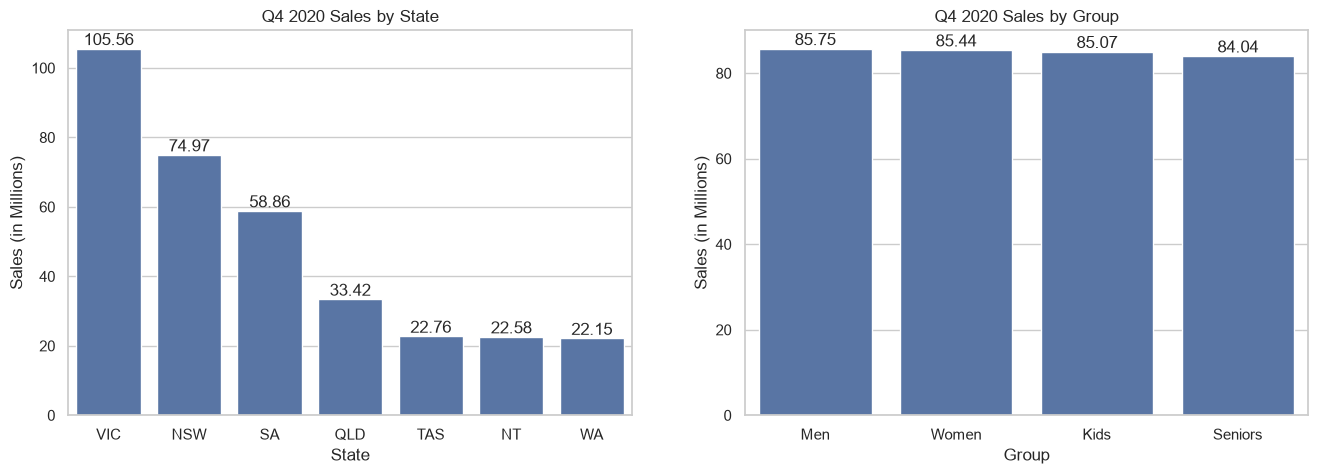


Q4 2020 Sales by State (in Millions) : 

State
VIC   105.56
NSW    74.97
SA     58.86
QLD    33.42
TAS    22.76
NT     22.58
WA     22.15

Q4 2020 Sales by Group (in Millions) : 

Group
Men       85.75
Women     85.44
Kids      85.07
Seniors   84.04


In [168]:
# Q4 total sales by State (Quarterly_State) and by Group (Group_Report)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(x=Quarterly_State.index, y=Quarterly_State['Q4'], ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt="%.2f")
axes[0].set_title("Q4 2020 Sales by State")
axes[0].set_xlabel("State")
axes[0].set_ylabel("Sales (in Millions)")

sns.barplot(x=Group_Report.index, y=Group_Report['Sales'] / 1000000, ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fmt="%.2f")
axes[1].set_title("Q4 2020 Sales by Group")
axes[1].set_xlabel("Group")
axes[1].set_ylabel("Sales (in Millions)")

plt.show()

print("\nQ4 2020 Sales by State (in Millions) : \n")
print(Quarterly_State['Q4'].round(2).to_string())
print("\nQ4 2020 Sales by Group (in Millions) : \n")
print((Group_Report['Sales'] / 1000000).round(2).to_string())

Observation

- From the Visualization of quarterly sales,
    - Q4 sales is 340.30 million. VIC is highest with 105.56 million and WA is lowest with 22.15 million
    - The groups have similar sales, with Men contributing 85.75 million and Seniors 84.04 million

In summary, the highest contributions in the quarter are from VIC, NSW and SA, and the 3 states at the lower contribution are WA, NT and TAS

3.b.5 DASHBOARD for the Head of Sales and Marketing

All the key charts in one view - Daily, Weekly, Monthly, Quarterly, State x Group, Group x State and Time of the day

Average daily sales (in Millions) :  3.78


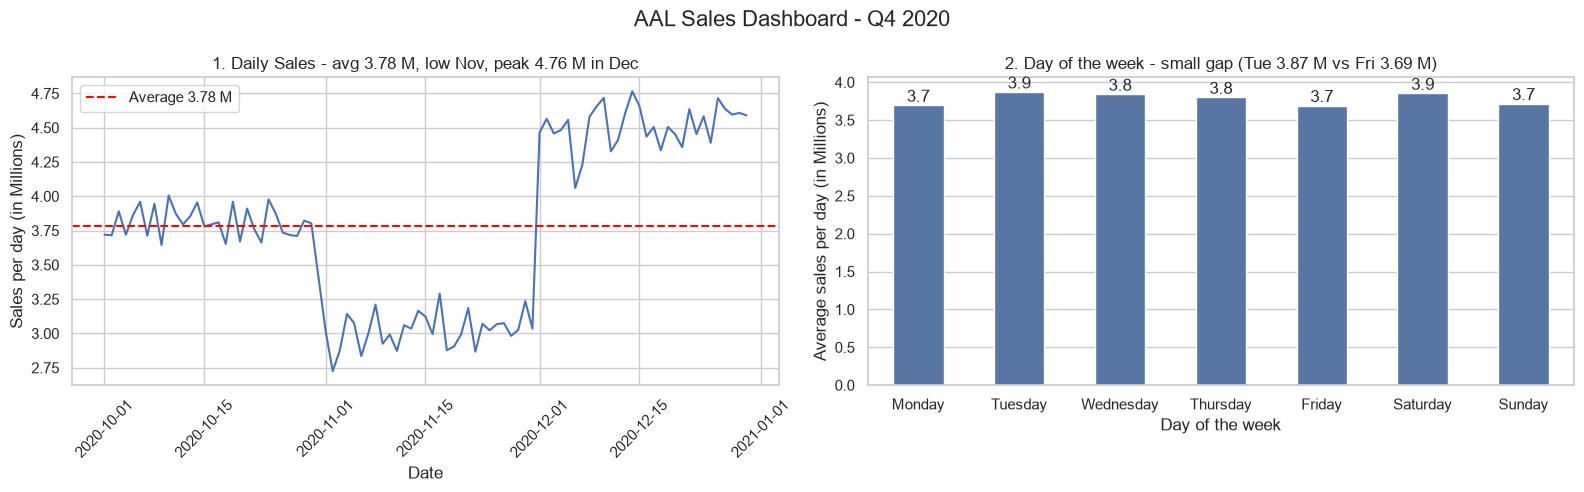

In [169]:
# Dashboard row 1 - Daily charts from 3.b.1
sns.set_theme(style="whitegrid")

Daily_Avg = Daily_Sales['Sales_in_Millions'].mean()
print("Average daily sales (in Millions) : ", round(Daily_Avg, 2))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.lineplot(x='Date', y='Sales_in_Millions', data=Daily_Sales, ax=axes[0])
axes[0].axhline(Daily_Avg, color="red", linestyle="--", label="Average " + str(round(Daily_Avg, 2)) + " M")
axes[0].set_title(f"1. Daily Sales - avg {round(Daily_Avg, 2)} M, low Nov, peak {round(Daily_Sales['Sales_in_Millions'].max(), 2)} M in Dec")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Sales per day (in Millions)")
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(loc="upper left")

sns.barplot(x=Weekday_Report.index, y=Weekday_Report['Sales_per_Day_in_Millions'], width=0.5, ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fmt="%.1f")
Wd = Weekday_Report['Sales_per_Day_in_Millions']
axes[1].set_title(f"2. Day of the week - small gap ({Wd.idxmax()[:3]} {round(Wd.max(), 2)} M vs {Wd.idxmin()[:3]} {round(Wd.min(), 2)} M)")
axes[1].set_xlabel("Day of the week")
axes[1].set_ylabel("Average sales per day (in Millions)")

fig.suptitle("AAL Sales Dashboard - Q4 2020", fontsize=16)
plt.tight_layout()
plt.show()

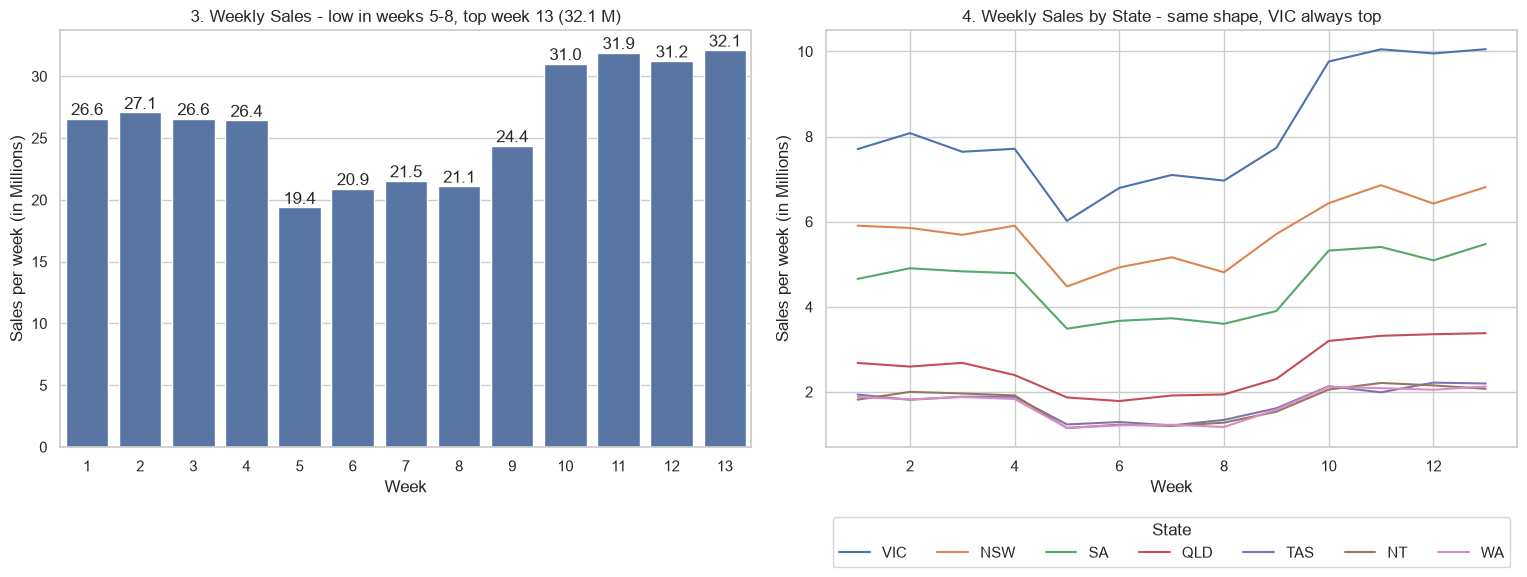

In [170]:
# Dashboard row 2 - Weekly charts from 3.b.2
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x='Week', y='Sales_in_Millions', data=Weekly_Report, ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt="%.1f")
Top_Week = Weekly_Report.loc[Weekly_Report['Sales_in_Millions'].idxmax()]
axes[0].set_title(f"3. Weekly Sales - low in weeks 5-8, top week {int(Top_Week['Week'])} ({Top_Week['Sales_in_Millions']:.1f} M)")
axes[0].set_xlabel("Week")
axes[0].set_ylabel("Sales per week (in Millions)")

sns.lineplot(data=Weekly_State, dashes=False, ax=axes[1])
axes[1].set_title("4. Weekly Sales by State - same shape, VIC always top")
axes[1].set_xlabel("Week")
axes[1].set_ylabel("Sales per week (in Millions)")
axes[1].legend(title="State", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=7)   # legend below the chart

plt.tight_layout()
plt.show()

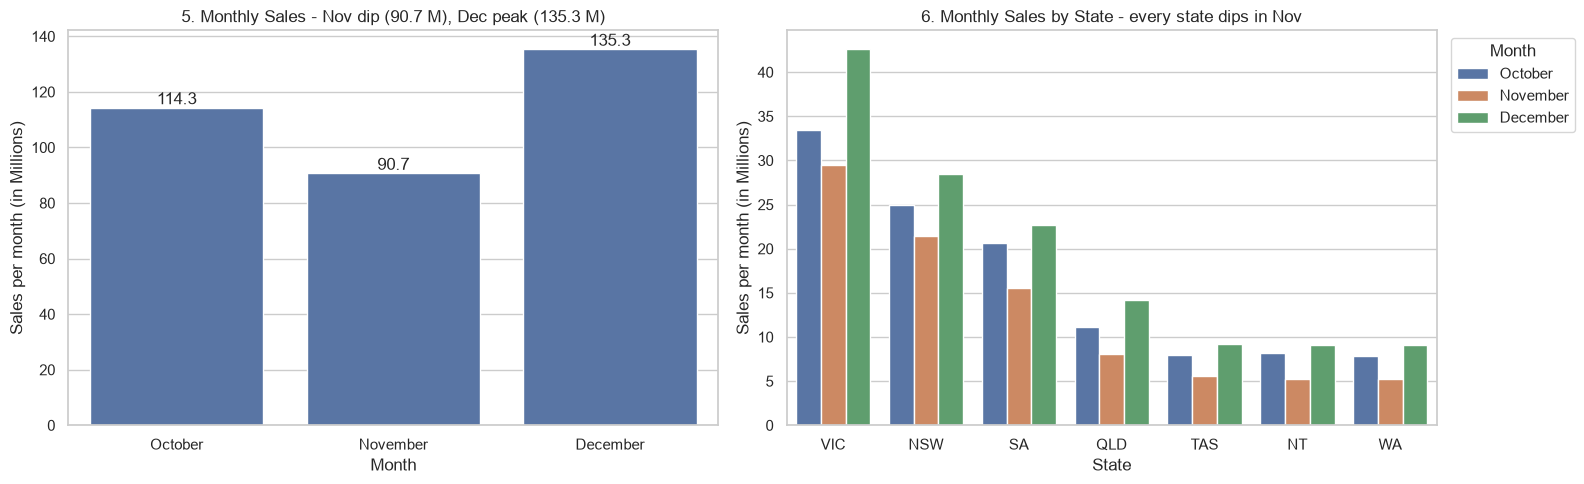

In [171]:
# Dashboard row 3 - Monthly charts from 3.b.3
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(x='Month_Name', y='Sales_in_Millions', data=Monthly_Report, ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt="%.1f")
axes[0].set_title(f"5. Monthly Sales - Nov dip ({Monthly_Report['Sales_in_Millions'].min():.1f} M), Dec peak ({Monthly_Report['Sales_in_Millions'].max():.1f} M)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Sales per month (in Millions)")

sns.barplot(x='State', y='Sales_in_Millions', hue='Month_Name', data=Monthly_State_Sales, order=State_Order, hue_order=['October', 'November', 'December'], ax=axes[1])
axes[1].set_title("6. Monthly Sales by State - every state dips in Nov")
axes[1].set_xlabel("State")
axes[1].set_ylabel("Sales per month (in Millions)")
axes[1].legend(title="Month", loc="upper left", bbox_to_anchor=(1.01, 1))   # legend outside the bars

plt.tight_layout()
plt.show()

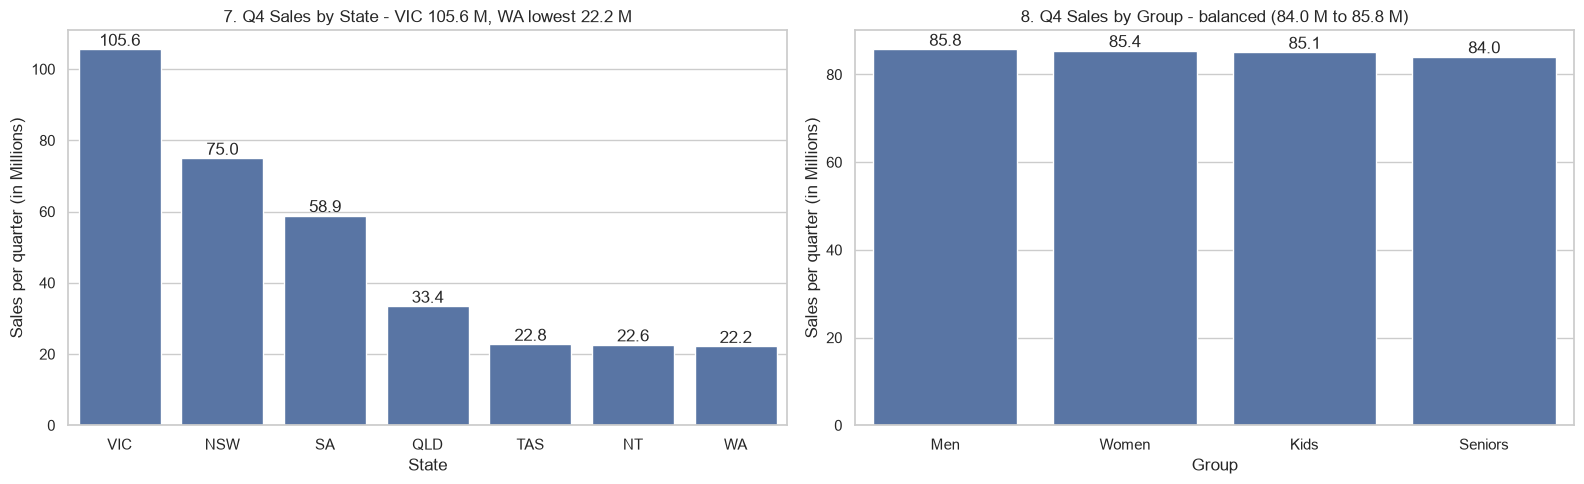

In [172]:
# Dashboard row 4 - Quarterly charts from 3.b.4
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(x=Quarterly_State.index, y=Quarterly_State['Q4'], ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt="%.1f")
axes[0].set_title(f"7. Q4 Sales by State - VIC {Quarterly_State.loc['VIC', 'Q4']:.1f} M, WA lowest {Quarterly_State.loc['WA', 'Q4']:.1f} M")
axes[0].set_xlabel("State")
axes[0].set_ylabel("Sales per quarter (in Millions)")

sns.barplot(x=Group_Report.index, y=Group_Report['Sales'] / 1000000, ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fmt="%.1f")
axes[1].set_title(f"8. Q4 Sales by Group - balanced ({Group_Report['Sales'].min() / 1000000:.1f} M to {Group_Report['Sales'].max() / 1000000:.1f} M)")
axes[1].set_xlabel("Group")
axes[1].set_ylabel("Sales per quarter (in Millions)")

plt.tight_layout()
plt.show()

Observation

- From the Visualization of the dashboard,
    - Daily sales are 3.78 million on average, with the highest day 2020-12-14 (4.76 million) and the lowest day 2020-11-02 (2.73 million)
    - Day of the week has only a small effect, Tuesday 3.87 million and Friday 3.69 million per day
    - Weekly sales are steady in weeks 1 to 4 (26.4 to 27.1 million), low in weeks 5 to 8 (19.4 to 21.5 million) and highest in week 13 (32.1 million)
    - December is the highest month (135.33 million), November the lowest (90.68 million) and October in the middle (114.29 million), and every state dips in November
    - Q4 total is 340.30 million, VIC is highest (105.56 million) and WA lowest (22.15 million), while the four groups are balanced (84.04 to 85.75 million)

3.c Recommended visualization package selection

RECOMMENDATION - SEABORN

Matplotlib, Seaborn and Plotly were considered. SEABORN is the recommended package for this project, and the reasons are

1. Seaborn works directly with the pandas DataFrame, the column names can be given as x, y and hue, so a State x Group or Time x Group chart needs only one line of code
2. Seaborn is made for statistical plotting. Box plot, histogram with kde and heatmap, which are needed for this project, are available in one line
3. The default style and colors are clean, so the charts are clear for the Head of S&M without much extra formatting
4. Seaborn is built on top of Matplotlib, so title, labels and size can still be controlled with the same plt commands

STEP4 : REPORT GENERATION

4.a Use JupyterLab Notebook for generating the report (data wrangling, analysis and visualization)

This notebook has the code, the outputs and the graphs together for STEP1 (wrangling), STEP2 (analysis) and STEP3 (visualization). The final cleaned data is saved to csv for future use.

In [173]:
# save the final cleaned data to csv

df.to_csv("Sales_Analysis_c_v2.csv", index=False)
print("\nFinal cleaned data is saved to Sales_Analysis_c_v2.csv")
print("Final dataset shape (rows, columns) : ", df.shape)


Final cleaned data is saved to Sales_Analysis_c_v2.csv
Final dataset shape (rows, columns) :  (7560, 15)


4.b Use Markdown in suitable places while presenting the report

Markdown is used for the headings (task numbers same as the problem statement), OBSERVATION, Conclusion, SUMMARY and RECOMMENDATIONS.

4.c Use suitable graphs, plots and analysis reports along with recommendations

Different plots are used for different aspects of the analysis - box plot for descriptive statistics, histogram with kde (distribution plot) for other statistical plotting, bar / line charts and heatmaps for the dashboard.

4.c.1 Use a box plot for descriptive statistics

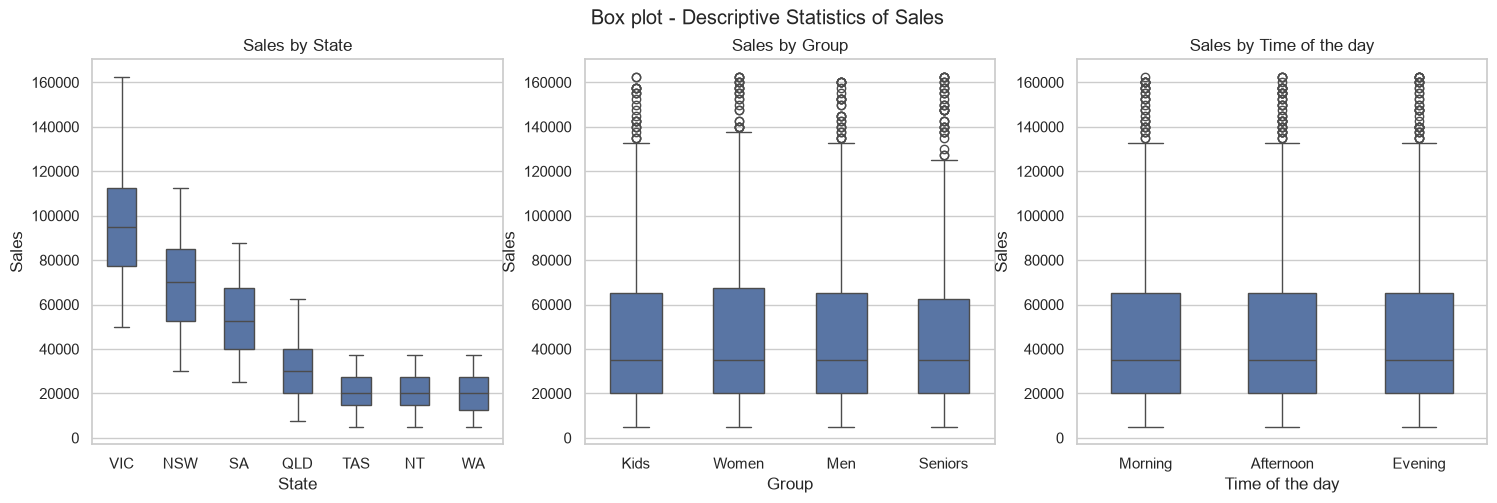

In [174]:
# Box plot of Sales for each State, Group and Time of the day in one view

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(x='State', y='Sales', data=df, order=State_Order, width=0.5, ax=axes[0])
axes[0].set_title("Sales by State")
axes[0].set_xlabel("State")
axes[0].set_ylabel("Sales")

sns.boxplot(x='Group', y='Sales', data=df, order=['Kids', 'Women', 'Men', 'Seniors'], width=0.5, ax=axes[1])
axes[1].set_title("Sales by Group")
axes[1].set_xlabel("Group")
axes[1].set_ylabel("Sales")

sns.boxplot(x='Time', y='Sales', data=df, order=['Morning', 'Afternoon', 'Evening'], width=0.5, ax=axes[2])
axes[2].set_title("Sales by Time of the day")
axes[2].set_xlabel("Time of the day")
axes[2].set_ylabel("Sales")

fig.suptitle("Box plot - Descriptive Statistics of Sales")
plt.show()

Conclusion

From the Visualization of the box plots, the following is identified:
- VIC has the highest box and the longest whisker, and WA, NT and TAS have the lowest boxes. No state has dots (outliers) against its own box
- The Group and Time of the day boxes are almost the same, and all the dots on the top of these boxes are VIC rows (the high value rows found with the IQR method in section 1.a.5)

4.c.2 Use the Seaborn distribution plot for any other statistical plotting

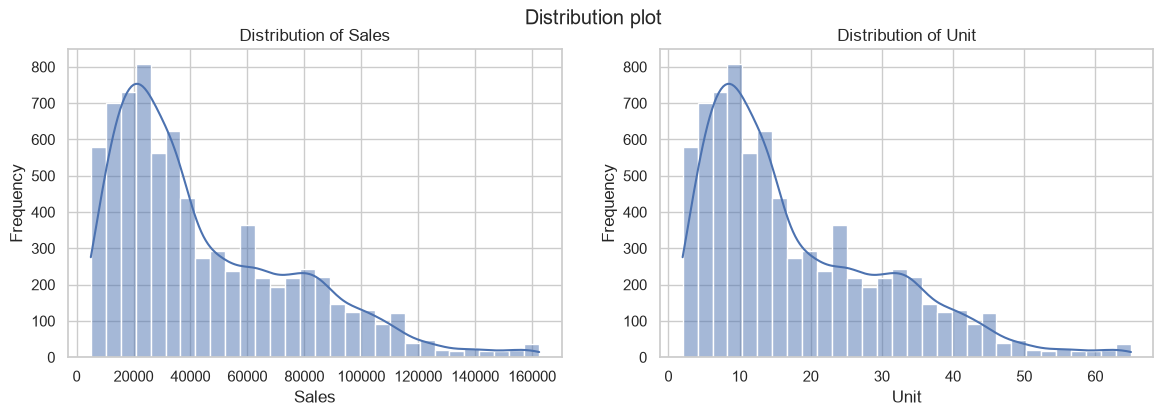

In [175]:
# Seaborn distribution plot (histogram with kde) of Sales and Unit

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df['Sales'], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Sales")
axes[0].set_xlabel("Sales")
axes[0].set_ylabel("Frequency")

sns.histplot(df['Unit'], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Unit")
axes[1].set_xlabel("Unit")
axes[1].set_ylabel("Frequency")

fig.suptitle("Distribution plot")
plt.show()

Observation

- From the Visualization of the Distribution plot of Sales and Unit,
    - Both plots have a high bar on the left side and a long tail on the right side, which confirms the right skew seen with Mean, Median and Mode in section 2.a
    - Sales and Unit have the same shape, because Sales is always Unit x 2500

4.c.3 Growth target for the low revenue states (illustration with the numbers of this quarter)

In [176]:
# If WA, NT and TAS reach the sales level of QLD (the next state), how much more sales will the company get ?

QLD_Sales = State_Report.loc['QLD', 'Sales']
Low3_Sales = State_Report.loc[['WA', 'NT', 'TAS'], 'Sales']
Extra_Sales = QLD_Sales * 3 - Low3_Sales.sum()
print("\nQLD sales                            : ", readable_number(QLD_Sales))
print("WA + NT + TAS sales                  : ", readable_number(Low3_Sales.sum()))
print("Extra sales if all 3 reach QLD       : ", readable_number(Extra_Sales))
print("Extra sales as % of Q4 total sales   : ", round(Extra_Sales / State_Report['Sales'].sum() * 100, 2))
print("QLD is above the average of the 3 states by (%) : ", round((QLD_Sales / Low3_Sales.mean() - 1) * 100, 2))


QLD sales                            :  33.42 Million
WA + NT + TAS sales                  :  67.49 Million
Extra sales if all 3 reach QLD       :  32.76 Million
Extra sales as % of Q4 total sales   :  9.63
QLD is above the average of the 3 states by (%) :  48.54


SUMMARY
========

The goal of this project was to analyze the Q4 2020 sales of AAL state by state, to find the high and low revenue states, and to suggest sales programs for them.

Data Wrangling
---------------------------

- Operations performed on the raw data - Removed extra spaces in text columns, fixed the Date data type, Missing / Duplicate / Incorrect values check, Outlier check and Min-Max Normalization. No row was removed and no value was capped, all 7,560 rows are used.
- 2 days (2020-10-31 and 2020-12-31) are not available in the data, they are not filled, and every month has 30 days of data, so the months are compared fairly (Sales per Day is also shown).

Data Analysis
---------------------------

- Q4 2020 total sales is 340.30 million from 136,121 units.
- Highest sales state is VIC (105.56 million, 31.02%), followed by NSW (74.97 million) and SA (58.86 million). These three make 70.35% of the sales.
- Lowest sales states are WA (22.15 million), NT (22.58 million) and TAS (22.76 million), with QLD (33.42 million) as the next state.
- Highest sales group is Men (85.75 million) and lowest is Seniors (84.04 million), but the difference is only 2.04%, all four groups are almost equal.
- Monthly : October 114.29 million, November 90.68 million and December 135.33 million. December is 49.23% higher than November.
- Weekly : steady in weeks 1 to 4, low in weeks 5 to 8 (lowest in total is week 5, 19.39 million), high in weeks 10 to 13 (highest is week 13, 32.12 million).
- Time of the day : Morning is the peak (114.21 million) and Evening is the off-peak (112.09 million). The gap is only 1.89%.

Dashboard
---------------------------

- Seaborn is recommended and used for the dashboard, with the box plot for descriptive statistics and the distribution plot (histplot) for the Sales and Unit distribution.

Business takeaway
---------------------------

The sales of AAL differ mostly by state and by month, and less by customer group or time of the day. The business is concentrated in VIC, NSW and SA, and the low revenue states (WA, NT, TAS) lose the most in November and rise strongly in December (QLD also rises strongly).

*This is one quarter of data only.

RECOMMENDATIONS
===============

Sales programs for the LOW revenue states (WA, NT, TAS)

1. NOVEMBER offer - WA, NT and TAS fall 33.72%, 36.06% and 30.82% in November, VIC and NSW fall only 11.70% and 14.07%. A November offer (for example bundle offers or loyalty points) in these 3 states is the first program
2. DECEMBER readiness - the same states rise 73.69%, 73.09% and 65.92% in December, so stock and staff should be ready by 1 December
3. GROWTH target - if WA, NT and TAS each reach the QLD level (33.42 million), the quarter gets 32.76 million more (9.63% of the total). QLD is 48.54% above the average of these three states, so it is a reachable first target
4. GROUP offers - in WA, Women are the lowest group (5.26 against Men 5.75 million, gap 9.31%), in TAS also Women (5.58 against Kids 5.78 million) and in NT Seniors (5.46 against Men 5.76 million). Women range in WA and TAS and Seniors range in NT can be tried first
5. VIC, NSW and SA give 70.35% of the sales, so stock and service in these states should be protected first

Peak and off-peak (time of the day) - hyper-personalization and Next Best Offer

1. Morning is the peak and Evening is the off-peak, but the gap is only 1.89%, so one time based campaign for all customers will not give much
2. Evening offers (for example free delivery or an evening discount) can be tested where the evening is weak: QLD (morning is 7.57% above evening), SA (afternoon is 3.39% above evening) and Seniors (morning is 4.80% above evening). An afternoon offer can be tested in WA (morning is 3.91% above afternoon)
3. In the peak time, a Next Best Offer (a higher value item or a bundle with the item bought) can be shown, as customers are already buying
4. Use a test group and a control group to measure the result, then expand to other states

Calendar and next steps

1. Plan stock and staff for weeks 10 to 13 (average 31.58 million per week, best day 2020-12-14 with 4.76 million) and promotions in weeks 5 to 8 (average 20.74 million per week)
2. Day of the week has a small effect (Tuesday 3.87 and Friday 3.69 million per day), so it is a second priority
3. More quarters of data are needed to confirm the yearly pattern, and cost / profit and customer level data to personalize the offers